# Section 15: Model Explainability (XAI)
Explains the **final model** chosen in the model-comparison section (read from `results/final_model.json`), using the saved modeling table, splits and fitted pipelines. Nothing is re-tuned here and no model selection decision depends on anything in this notebook.

| Part | What it does |
|---|---|
| 15.1 | Finds and loads the artifacts, checks that the loaded model reproduces the saved predictions |
| 15.2 | What is being explained, on which rows, against which reference data, and how to read the results |
| 15.3 | **Global 1: permutation importance** (single features, feature groups, other models, validation vs test) |
| 15.4 | Does the explanation depend on the random seed of the network? |
| 15.5 | **Global 2: SHAP** (bar, beeswarm, group SHAP, dependence plots) and agreement with permutation importance |
| 15.6 | Sensitivity checks: SHAP background choice, TreeSHAP on XGBoost as an independent cross-check |
| 15.7 | **Local explanations**: SHAP waterfall and LIME for individual driver-race rows |
| 15.8 | Written conclusions (computed from the tables above), limitations, saved files |

**Read this before quoting any result.** Every explanation below describes *what the fitted model relies on to produce its scores*. None of it shows what causes a podium. A feature can be important to the model because it is correlated with something that matters (a fast car, a strong qualifying lap) without having any effect of its own. This distinction is repeated where the results are interpreted.

## 15.1 Setup, artifacts and sanity checks

Inputs (all written by the earlier notebooks):

| File | Written by | Used for |
|---|---|---|
| `clean/modeling_table.parquet`, `clean/feature_config.json` | feature engineering (Section 12) | rows, features, groups, time split |
| `results/final_model.json`, `results/<name>_model.joblib`, `results/<name>.json`, `results/<name>_preds.parquet` | statistical models and neural network notebooks | the fitted pipelines, thresholds, saved predictions |
| `clean/drivers.parquet`, `races.parquet`, `constructors.parquet`, `results.parquet`, `status.parquet` | cleaning notebook | readable names for the local explanations (display only, never features) |

Outputs: figures in `figures_xai/`, tables in `xai_outputs/`.

In [1]:
# Setup: install any missing library, then continue. Safe to re-run.
import importlib.util, subprocess, sys
for _mod, _pip in [("shap", "shap"), ("lime", "lime"), ("xgboost", "xgboost"), ("pyarrow", "pyarrow"), ("joblib", "joblib")]:
    if importlib.util.find_spec(_mod) is None:
        print(f"installing {_pip} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])
        except Exception as e:
            print(f"  could not install {_pip}: {e}")
print("setup done")

installing lime ...
setup done


In [2]:
import os, glob, json, math, time, copy, itertools, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
import shap
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAVE_LIME = True
except Exception as _e:
    HAVE_LIME = False
    print("LIME not available, the LIME parts will be skipped:", _e)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
SEED = 42
np.random.seed(SEED)

# ------------------------------- settings (the only things you may want to change) -----------------------------
MODEL_TO_EXPLAIN = "final"   # "final" = whatever results/final_model.json says; or a key such as "nn", "xgb", "logreg", "rf"
N_REPEATS = 30               # repeats for permutation importance (validation and test)
N_REPEATS_CROSS = 10         # repeats for the cross-model and cross-seed permutation comparisons
BACKGROUND_FROM_YEAR = 2014  # SHAP/LIME reference data = training rows from this season on (hybrid era, full qualifying data)
BACKGROUND_SIZE = 100        # rows in the SHAP background
N_PERMUTATIONS = 6           # SHAP permutation passes per row (each pass visits every feature twice)
N_EXPLAIN = None             # None = explain every test row; an int = random subset of that many rows
TOP_K = 15                   # features shown in bar charts
LIME_SAMPLES = 5000          # perturbed samples per LIME explanation
LIME_SEEDS = 5               # repeats of LIME per case, for the stability check
RUN_SEED_CHECK = True        # retrain the network with 3 seeds (needs the NN recipe, ~10 s)
RUN_XGB_CROSSCHECK = True    # TreeSHAP on the saved XGBoost model

In [3]:
def locate(name, subdirs=("", "clean", "results", "models")):
    # looks next to the notebook, one level up, in /kaggle/working, then searches /kaggle/input and the working directory
    bases = [b for b in [os.environ.get("F1_ROOT"), os.getcwd(), os.path.dirname(os.getcwd()), "/kaggle/working"] if b]
    for b in bases:
        for s in subdirs:
            p = os.path.join(b, s, name)
            if os.path.exists(p): return p
    for b in [os.getcwd(), "/kaggle/working", "/kaggle/input"]:
        if os.path.isdir(b):
            hits = sorted(glob.glob(os.path.join(b, "**", name), recursive=True))
            if hits: return hits[0]
    return None

def need(name):
    p = locate(name)
    if p is None:
        raise FileNotFoundError(f"{name} not found. Run the earlier notebooks (they write it) or attach their output, or set the F1_ROOT environment variable.")
    return p

p_cfg, p_final = need("feature_config.json"), need("final_model.json")
p_table = locate("modeling_table.parquet") or need("modeling_table.csv")
CLEAN, RESULTS = os.path.dirname(p_cfg), os.path.dirname(p_final)
OUT_ROOT = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.dirname(os.path.abspath(RESULTS))
FIG_DIR, TAB_DIR = os.path.join(OUT_ROOT, "figures_xai"), os.path.join(OUT_ROOT, "xai_outputs")
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

cfg = json.load(open(p_cfg))
mdl = pd.read_parquet(p_table) if p_table.endswith(".parquet") else pd.read_csv(p_table)
TARGET, FEATURES = cfg["target"], list(cfg["features"])
BINARY, CONTINUOUS = list(cfg["binary"]), list(cfg["continuous"])
FEATURE_GROUPS = {g: list(f) for g, f in cfg["groups"].items()}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
mdl = mdl.sort_values(["race_order", "driverId"]).reset_index(drop=True)
train, val, test = (mdl[mdl["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))

assert set(FEATURES) <= set(mdl.columns) and set(BINARY) | set(CONTINUOUS) == set(FEATURES) and set(group_of) == set(FEATURES)
assert not mdl.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert train["race_order"].max() < val["race_order"].min() and val["race_order"].max() < test["race_order"].min()
group_colors = dict(zip(FEATURE_GROUPS, plt.cm.tab10.colors))

print(f"modeling table: {p_table}\nresults folder: {RESULTS}\noutputs: {FIG_DIR} , {TAB_DIR}")
print(f"{len(FEATURES)} features ({len(BINARY)} binary) in groups { {g: len(f) for g, f in FEATURE_GROUPS.items()} }")
print(f"train {len(train):,} ({train['year'].min()}-{train['year'].max()}) | val {len(val):,} ({val['year'].min()}-{val['year'].max()}) | "
      f"test {len(test):,} ({test['year'].min()}-{test['year'].max()}) | podium rate train/val/test = "
      f"{train[TARGET].mean():.3f}/{val[TARGET].mean():.3f}/{test[TARGET].mean():.3f}")

modeling table: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\clean\modeling_table.parquet
results folder: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\results
outputs: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai , a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs
29 features (4 binary) in groups {'grid': 6, 'qualifying': 4, 'driver_form': 4, 'constructor_form': 2, 'standings': 6, 'circuit_history': 3, 'context': 4}
train 22,441 (1950-2019) | val 774 (2020-2021) | test 1,351 (2022-2024) | podium rate train/val/test = 0.135/0.151/0.151


In [4]:
# ---- the neural-network recipe, copied unchanged from nn_models.ipynb (Sections 2-3) ------------------------------
# Used (a) as a fallback if the saved .joblib cannot be loaded with the library versions installed here, and
# (b) for the seed-stability check in 15.4. It trains on train rows only and early-stops on validation PR-AUC.
def make_preprocessor_nn():
    cont = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)), ("sc", StandardScaler())])
    return ColumnTransformer([("cont", cont, CONTINUOUS),
                              ("bin", SimpleImputer(strategy="most_frequent", keep_empty_features=True), BINARY)])

def train_nn_pipeline(hidden=(64,), alpha=1e-3, lr=1e-3, batch=256, max_epochs=200, patience=15, seed=SEED):
    pre = make_preprocessor_nn().fit(train[FEATURES])
    X_tr, X_va = pre.transform(train[FEATURES]), pre.transform(val[FEATURES])
    y_tr, y_va = train[TARGET].to_numpy(), val[TARGET].to_numpy()
    pos_w = (y_tr == 0).sum() / (y_tr == 1).sum()
    rng = np.random.default_rng(seed)
    def weighted_epoch():
        pos, neg = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
        reps = int(np.floor(pos_w)); extra = rng.random(len(pos)) < (pos_w - reps)
        idx = np.concatenate([neg, np.repeat(pos, reps), pos[extra]]); rng.shuffle(idx)
        return X_tr[idx], y_tr[idx]
    net = MLPClassifier(hidden_layer_sizes=tuple(hidden), activation="relu", solver="adam", alpha=alpha,
                        learning_rate_init=lr, batch_size=batch, random_state=seed)
    best, best_score, wait = None, -np.inf, 0
    for epoch in range(1, max_epochs + 1):
        Xe, ye = weighted_epoch(); net.partial_fit(Xe, ye, classes=[0, 1])
        score = average_precision_score(y_va, net.predict_proba(X_va)[:, 1])
        if score > best_score + 1e-4: best, best_score, wait = copy.deepcopy(net), score, 0
        else:
            wait += 1
            if wait >= patience: break
    return Pipeline([("pre", pre), ("clf", best)]), float(best_score)

In [5]:
# ---- load every saved model (shared format written by both modeling notebooks) ------------------------------------
final_meta = json.load(open(p_final))
FINAL_KEY = final_meta["final_model"]
EXPLAIN_KEY = FINAL_KEY if MODEL_TO_EXPLAIN == "final" else MODEL_TO_EXPLAIN

META, PREDS, MODELS, LOAD_NOTES = {}, {}, {}, {}
for f in sorted(glob.glob(os.path.join(RESULTS, "*_model.joblib"))):
    key = os.path.basename(f)[:-len("_model.joblib")]
    if not (os.path.exists(os.path.join(RESULTS, f"{key}.json")) and os.path.exists(os.path.join(RESULTS, f"{key}_preds.parquet"))):
        continue
    META[key] = json.load(open(os.path.join(RESULTS, f"{key}.json")))
    PREDS[key] = pd.read_parquet(os.path.join(RESULTS, f"{key}_preds.parquet")).set_index("resultId")["p"]
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            MODELS[key] = joblib.load(f)
        vers = [str(w.message)[:160] for w in caught if "version" in str(w.message).lower()]
        LOAD_NOTES[key] = "loaded" + (f" (version warning: {vers[0]})" if vers else "")
    except Exception as e:
        LOAD_NOTES[key] = f"FAILED to load ({type(e).__name__}: {str(e)[:120]})"

if EXPLAIN_KEY not in META:
    raise KeyError(f"model '{EXPLAIN_KEY}' not found in {RESULTS}; available: {list(META)}")
if EXPLAIN_KEY not in MODELS:
    if EXPLAIN_KEY != "nn":
        raise RuntimeError(f"{EXPLAIN_KEY} could not be loaded and only the neural network has a rebuild recipe: {LOAD_NOTES[EXPLAIN_KEY]}")
    prm = META["nn"]["params"]
    print("Rebuilding the neural network from its saved settings (the joblib did not load):", prm)
    MODELS["nn"], _ = train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=prm.get("seed", SEED))
    LOAD_NOTES["nn"] += " -> rebuilt with the saved recipe"

LABEL = {k: m["model"] for k, m in META.items()}
THRESHOLD = {k: float(m["threshold"]) for k, m in META.items()}
model = MODELS[EXPLAIN_KEY]
print("Models found:", {LABEL[k]: LOAD_NOTES[k] for k in META})
print(f"\nExplained model: {LABEL[EXPLAIN_KEY]} ('{EXPLAIN_KEY}'), validation-chosen threshold {THRESHOLD[EXPLAIN_KEY]:.3f}"
      f" | final model per final_model.json: {LABEL.get(FINAL_KEY, FINAL_KEY)}")

Rebuilding the neural network from its saved settings (the joblib did not load): {'hidden': [64, 32], 'alpha': 0.01, 'lr': 0.001, 'epochs': 8, 'seed': 42, 'seed_pr_auc_std': 0.0074156464635919805}
Models found: {'Logistic regression': "FAILED to load (AttributeError: Can't get attribute '_RemainderColsList' on <module 'sklearn.compose._column_transformer' from 'a:\\\\Anaconda\\\\Lib\\\\site-)", 'Shallow NN': "FAILED to load (AttributeError: Can't get attribute '_RemainderColsList' on <module 'sklearn.compose._column_transformer' from 'a:\\\\Anaconda\\\\Lib\\\\site-) -> rebuilt with the saved recipe", 'Random forest': "FAILED to load (AttributeError: Can't get attribute '_RemainderColsList' on <module 'sklearn.compose._column_transformer' from 'a:\\\\Anaconda\\\\Lib\\\\site-)", 'XGBoost': "FAILED to load (AttributeError: Can't get attribute '_RemainderColsList' on <module 'sklearn.compose._column_transformer' from 'a:\\\\Anaconda\\\\Lib\\\\site-)"}

Explained model: Shallow NN ('nn'), v

In [6]:
# ---- sanity check: does the loaded model reproduce the predictions that were saved when it was evaluated? ----------
def predict_p(m, d): return m.predict_proba(d[FEATURES])[:, 1]

def top3_precision_arr(y, p, race):
    dd = pd.DataFrame(dict(y=y, p=p, r=race)).sort_values(["r", "p"], ascending=[True, False])
    return float(dd.groupby("r").head(3)["y"].mean())

def metrics_at(d, p, thr):
    y = d[TARGET].to_numpy(); yhat = (np.asarray(p) >= thr).astype(int)
    return dict(roc_auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p), f1=f1_score(y, yhat, zero_division=0),
                precision=precision_score(y, yhat, zero_division=0), recall=recall_score(y, yhat, zero_division=0),
                top3_precision=top3_precision_arr(y, np.asarray(p), d["raceId"].to_numpy()))

rows = []
for key, m in MODELS.items():
    for sp, d in (("val", val), ("test", test)):
        p = predict_p(m, d)
        saved = PREDS[key].reindex(d["resultId"]).to_numpy()
        rows.append(dict(model=LABEL[key], key=key, split=sp, max_abs_diff_vs_saved=float(np.nanmax(np.abs(p - saved))),
                         **metrics_at(d, p, THRESHOLD[key])))
check = pd.DataFrame(rows)
display(check.pivot(index="model", columns="split", values=["pr_auc", "roc_auc", "f1", "max_abs_diff_vs_saved"]).round(4))
d_expl = check[(check["key"] == EXPLAIN_KEY)]["max_abs_diff_vs_saved"].max()
if d_expl < 1e-6:
    print(f"OK: the loaded {LABEL[EXPLAIN_KEY]} reproduces the saved predictions exactly (max abs difference {d_expl:.1e}).")
else:
    print(f"WARNING: the loaded {LABEL[EXPLAIN_KEY]} differs from the saved predictions by up to {d_expl:.3g}. "
          "Either the library versions installed here differ from the ones used for training, or the model was rebuilt from its saved recipe (see the loading message above). Explanations below describe the model "
          "as it behaves in THIS environment; re-run the modeling notebooks here if the difference matters.")
test_rank = check[check["split"] == "test"].sort_values("pr_auc", ascending=False)["key"].tolist()
print(f"Test PR-AUC rank of the explained model: {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)} "
      f"(validation rank {check[check['split']=='val'].sort_values('pr_auc', ascending=False)['key'].tolist().index(EXPLAIN_KEY) + 1}).")

pr_auc         roc_auc             f1         max_abs_diff_vs_saved     
split         test     val    test     val   test     val                  test  val
model                                                                               
Shallow NN  0.6888  0.7479  0.9177  0.9275  0.644  0.7126                   0.0  0.0

OK: the loaded Shallow NN reproduces the saved predictions exactly (max abs difference 5.6e-16).
Test PR-AUC rank of the explained model: 1 of 1 (validation rank 1).


## 15.2 What is explained, on which rows, and how to read it

**Rows explained.** The test seasons (2022 onwards). Explaining is not model selection: no threshold, hyperparameter or feature choice is revisited, so using the test rows here does not break the rule that selection uses train and validation only. Validation rows are used as a second, independent look at permutation importance, to see whether the picture is stable.

**Reference ("background") data.** SHAP and LIME describe a prediction *relative to a reference population*. The reference here is a random sample of **training rows from the hybrid era (2014 to the end of train)**. Reasons: qualifying data is complete in these seasons, the cars and field size are closest to the test seasons, and nothing from validation or test is used. A reference drawn from the whole training history (1950 onward) would be dominated by early-era rows where qualifying features are missing, which would change what the baseline means. 15.6 measures how much this choice matters.

**What the model's output is.** The networks and linear/forest models were trained with the podium class up-weighted (about 6.4 to 1), so their probabilities are **not calibrated**: they are scores that rank drivers, and they average well above the true podium rate. SHAP values below are in units of this model score (a "probability-like" scale from 0 to 1), so a bar of +0.2 means "raises the score by 0.2", not "raises the chance of a podium by 20 points".

**Methods.**

| Method | Question it answers | Main weakness |
|---|---|---|
| Permutation importance | How much does test performance drop if one feature (or group) is scrambled across rows? | Correlated features share credit and each looks less important than the pair; scrambling creates unrealistic rows |
| SHAP (permutation explainer) | How much does each feature move this prediction away from the reference average? Averaged over rows = global importance | Depends on the reference data; also creates unrealistic feature combinations; credit split among correlated features |
| LIME | What does a simple model fitted around this one point say? | Random sampling: explanations can change between runs; only valid very close to the point |

**Correlated features.** The feature-engineering notebook found `grid_clean` and `quali_pos` almost perfectly rank-correlated (rho about 0.98) and kept both on purpose. For such pairs, single-feature methods split or hide the credit. Two remedies are used below: **grouped** permutation importance and **group SHAP** (sum of SHAP values inside a feature group), which are not affected by credit-splitting inside a group.

## 15.3 Global explanation 1: permutation importance

For each feature, the column is shuffled across rows of the evaluation set (the whole pipeline is applied afterwards, so missing indicators and scaling stay consistent) and the score is recomputed. The **drop in score** is the importance. Repeating the shuffle `N_REPEATS` times gives a spread: a feature is called reliably used when `mean drop - 2 x std > 0`.

The primary metric of the project is **PR-AUC**, so it is the headline here. ROC-AUC and the race-aware top-3 precision are computed in the same pass and saved.

Agreement between two importance rankings is reported two ways, because a plain Spearman correlation over all features is dominated by the many features with almost no importance (their order is noise). `spearman_all` uses every feature; `spearman_top` uses only the features in the top 10 of either ranking; `overlap_top` counts how many of the top 10 are shared.

In [7]:
def agreement(a, b, k=10):
    a, b = pd.Series(a), pd.Series(b).reindex(pd.Series(a).index)
    ta, tb = a.sort_values(ascending=False).head(k).index, b.sort_values(ascending=False).head(k).index
    top = list(dict.fromkeys(list(ta) + list(tb)))
    return dict(spearman_all=float(spearmanr(a, b).statistic), spearman_top=float(spearmanr(a[top], b[top]).statistic) if len(top) > 2 else np.nan,
                overlap_top=len(set(ta) & set(tb)), k=k, n_union=len(top))

In [8]:
def perm_importance(m, d, n_repeats=N_REPEATS, seed=SEED):
    race = d["raceId"].to_numpy()
    scorers = {"pr_auc": lambda est, X, y: average_precision_score(y, est.predict_proba(X)[:, 1]),
               "roc_auc": lambda est, X, y: roc_auc_score(y, est.predict_proba(X)[:, 1]),
               "top3_precision": lambda est, X, y: top3_precision_arr(y, est.predict_proba(X)[:, 1], race)}
    r = permutation_importance(m, d[FEATURES], d[TARGET].to_numpy(), scoring=scorers, n_repeats=n_repeats, random_state=seed, n_jobs=1)
    out = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES]})
    for k in scorers:
        out[f"{k}_drop"], out[f"{k}_std"] = r[k].importances_mean, r[k].importances_std
    out["reliable"] = (out["pr_auc_drop"] - 2 * out["pr_auc_std"]) > 0
    return out

t0 = time.time()
PI = {"validation": perm_importance(model, val), "test": perm_importance(model, test)}
print(f"permutation importance ({N_REPEATS} repeats x {len(FEATURES)} features x 2 sets) in {time.time()-t0:.0f}s")
base_scores = {sp: metrics_at(d, predict_p(model, d), THRESHOLD[EXPLAIN_KEY]) for sp, d in (("validation", val), ("test", test))}
print("unshuffled scores (PR-AUC):", {k: round(v["pr_auc"], 4) for k, v in base_scores.items()})
tab = (PI["test"][["feature", "group", "pr_auc_drop", "pr_auc_std", "roc_auc_drop", "top3_precision_drop", "reliable"]]
       .rename(columns={"pr_auc_drop": "test_pr_auc_drop", "pr_auc_std": "test_pr_auc_std", "roc_auc_drop": "test_roc_auc_drop",
                        "top3_precision_drop": "test_top3_drop", "reliable": "test_reliable"})
       .merge(PI["validation"][["feature", "pr_auc_drop", "pr_auc_std", "reliable"]].rename(columns={"pr_auc_drop": "val_pr_auc_drop", "pr_auc_std": "val_pr_auc_std", "reliable": "val_reliable"}), on="feature")
       .sort_values("test_pr_auc_drop", ascending=False).reset_index(drop=True))
PI_TABLE = tab
display(tab.head(TOP_K).round(4))
print(f"Reliably used (mean - 2 std > 0) on test: {int(tab['test_reliable'].sum())} of {len(tab)} features | on validation: {int(tab['val_reliable'].sum())} of {len(tab)}")

permutation importance (30 repeats x 29 features x 2 sets) in 29s
unshuffled scores (PR-AUC): {'validation': 0.7479, 'test': 0.6888}


,feature,group,test_pr_auc_drop,test_pr_auc_std,test_roc_auc_drop,test_top3_drop,test_reliable,val_pr_auc_drop,val_pr_auc_std,val_reliable
0,quali_pos,qualifying,0.0709,0.0131,0.0242,0.0693,True,0.0458,0.0164,True
1,grid_clean,grid,0.0642,0.0132,0.0216,0.0668,True,0.0498,0.0181,True
2,team_best_grid,grid,0.0309,0.0108,0.0119,0.0315,True,0.0212,0.0128,False
3,con_wins_prev,standings,0.0202,0.0091,0.0021,0.0253,True,0.0007,0.0073,False
4,drv_career_podium_rate,driver_form,0.0141,0.0026,0.0106,0.0116,True,0.0182,0.0053,True
5,con_pts_share_prev,standings,0.0113,0.0058,0.0053,0.0078,False,0.0124,0.0063,False
6,season_progress,context,0.0112,0.0046,0.0025,0.0134,True,0.0173,0.0099,False
7,drv_wins_prev,standings,0.0071,0.0035,0.0030,0.0100,True,0.0272,0.0048,True
8,front_row,grid,0.0067,0.0023,0.0019,-0.0002,True,0.0025,0.0039,False
9,con_champ_pos_prev,standings,0.0056,0.0029,-0.0002,0.0087,False,0.0188,0.0093,True


Reliably used (mean - 2 std > 0) on test: 9 of 29 features | on validation: 12 of 29


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_val_test.png


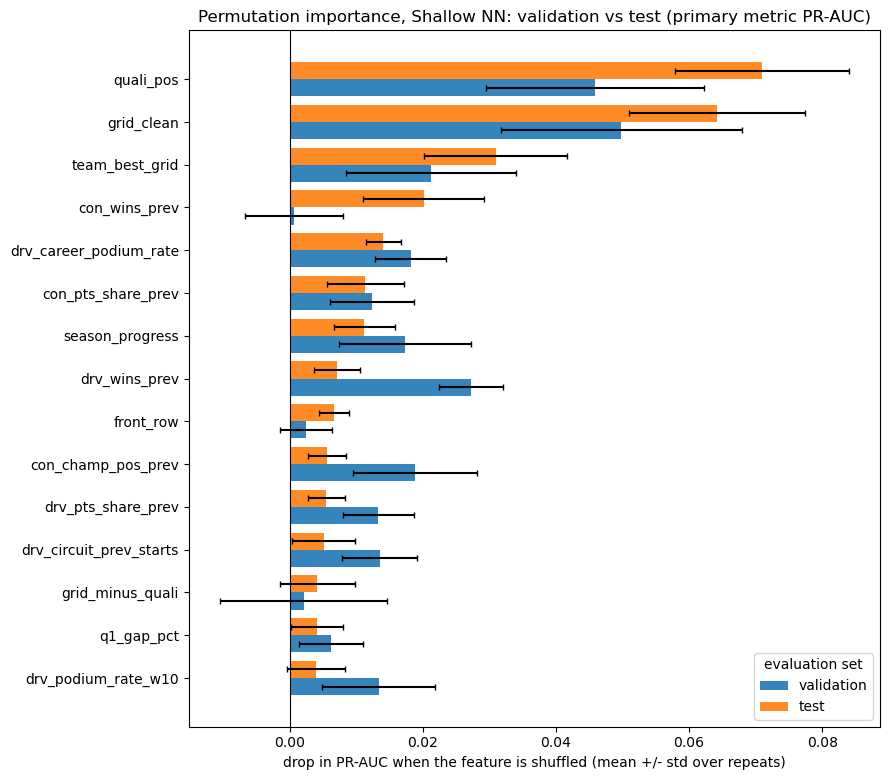

Rank agreement validation vs test: Spearman over all 29 features 0.33 | over the top-10 union (14 features) 0.01 | top-10 overlap 6 of 10
Top-5 shared: ['grid_clean', 'quali_pos']


In [9]:
def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name); fig.savefig(path, dpi=150, bbox_inches="tight"); print("Saved figure:", path); plt.show()

def plot_perm(pi_dict, title, fname, metric="pr_auc", top=TOP_K):
    key = f"{metric}_drop"; ref = list(pi_dict.values())[-1]
    order = ref.sort_values(key, ascending=False).head(top)["feature"].tolist()[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * top + 1.6)); h = 0.8 / len(pi_dict)
    for j, (lab, pi) in enumerate(pi_dict.items()):
        s = pi.set_index("feature").loc[order]
        ax.barh(np.arange(len(order)) + (j - (len(pi_dict) - 1) / 2) * h, s[key], h, xerr=s[f"{metric}_std"], capsize=2, label=lab,
                color=[group_colors[group_of[f]] for f in order] if len(pi_dict) == 1 else None, alpha=0.9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(f"drop in {metric.replace('_', '-').upper()} when the feature is shuffled (mean +/- std over repeats)"); ax.set_title(title)
    if len(pi_dict) > 1: ax.legend(title="evaluation set")
    else:
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for g, c in group_colors.items() if g in {group_of[f] for f in order}],
                  labels=[g for g in group_colors if g in {group_of[f] for f in order}], fontsize=8, loc="lower right")
    fig.tight_layout(); return fig

save_fig(plot_perm(PI, f"Permutation importance, {LABEL[EXPLAIN_KEY]}: validation vs test (primary metric PR-AUC)", "perm_importance_val_test.png"), "perm_importance_val_test.png")

# do the two evaluation sets agree on the ranking?
AG_VT = agreement(PI["validation"].set_index("feature")["pr_auc_drop"], PI["test"].set_index("feature")["pr_auc_drop"])
print(f"Rank agreement validation vs test: Spearman over all {len(FEATURES)} features {AG_VT['spearman_all']:.2f} | over the top-10 union ({AG_VT['n_union']} features) {AG_VT['spearman_top']:.2f} | top-10 overlap {AG_VT['overlap_top']} of 10")
top_v, top_t = (set(PI[s].sort_values("pr_auc_drop", ascending=False).head(5)["feature"]) for s in ("validation", "test"))
print(f"Top-5 shared: {sorted(top_v & top_t)}")

### 15.3.1 Feature groups (shuffling a whole group at once)

Single-feature importance understates features that have close substitutes. Here every column of a group is shuffled with the **same row permutation** (so the group stays internally consistent but is decoupled from the target and from the other groups). This is the explanation-side counterpart of the feature-group ablation: permutation measures how much the *fitted* model uses a group, ablation measures how much a model *retrained* without the group loses. They can disagree, because a retrained model can compensate with other groups.

,group,n_features,pr_auc_drop,pr_auc_std,roc_auc_drop,roc_auc_std,sum_of_single_feature_drops,group_minus_sum
0,grid,6,0.1780,0.0229,0.0714,0.0081,0.1040,0.0741
1,standings,6,0.0797,0.0143,0.0191,0.0031,0.0493,0.0304
2,qualifying,4,0.0717,0.0139,0.0229,0.0071,0.0805,-0.0088
3,context,4,0.0115,0.0075,0.0003,0.0021,0.0116,-0.0001
4,constructor_form,2,0.0112,0.0066,0.0097,0.0027,0.0061,0.0051
5,driver_form,4,0.0103,0.0075,0.0116,0.0033,0.0247,-0.0145
6,circuit_history,3,-0.0063,0.0066,-0.0020,0.0020,0.0067,-0.0130


group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_groups.png


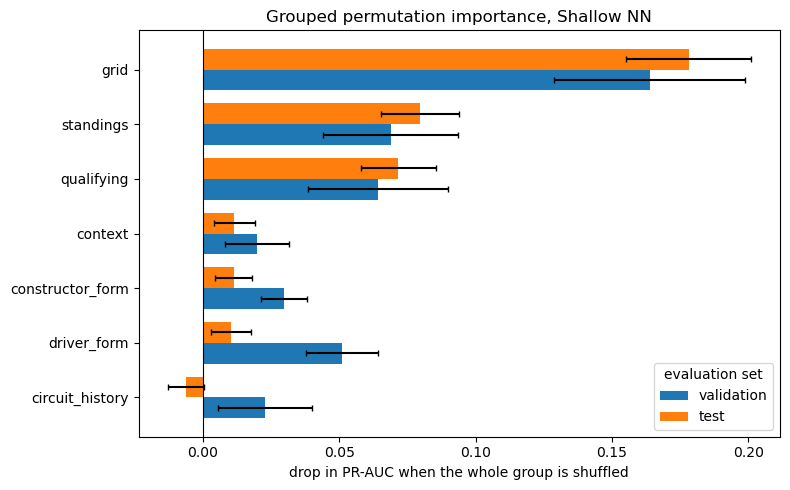

In [10]:
def grouped_perm(m, d, groups, n_repeats=N_REPEATS, seed=SEED):
    rng = np.random.default_rng(seed); race = d["raceId"].to_numpy(); y = d[TARGET].to_numpy()
    X0 = d[FEATURES]
    score = lambda X: (average_precision_score(y, m.predict_proba(X)[:, 1]), roc_auc_score(y, m.predict_proba(X)[:, 1]))
    b_pr, b_roc = score(X0); rows = []
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X0.copy(); perm = rng.permutation(len(d)); Xp[cols] = X0[cols].to_numpy()[perm]
            pr, roc = score(Xp); drops.append((b_pr - pr, b_roc - roc))
        drops = np.array(drops)
        rows.append(dict(group=g, n_features=len(cols), pr_auc_drop=drops[:, 0].mean(), pr_auc_std=drops[:, 0].std(),
                         roc_auc_drop=drops[:, 1].mean(), roc_auc_std=drops[:, 1].std()))
    return pd.DataFrame(rows).sort_values("pr_auc_drop", ascending=False).reset_index(drop=True)

GPI = {sp: grouped_perm(model, d, FEATURE_GROUPS) for sp, d in (("validation", val), ("test", test))}
single_sum = PI["test"].groupby("group")["pr_auc_drop"].sum()
g_tab = GPI["test"].assign(sum_of_single_feature_drops=lambda t: t["group"].map(single_sum))
g_tab["group_minus_sum"] = g_tab["pr_auc_drop"] - g_tab["sum_of_single_feature_drops"]
GROUP_PI_TABLE = g_tab
display(g_tab.round(4))
print("group_minus_sum > 0 means the group matters more than its features' separate drops add up to (the features are substitutes for each other).")

fig, ax = plt.subplots(figsize=(8, 0.5 * len(FEATURE_GROUPS) + 1.5)); h = 0.38
order = GPI["test"].sort_values("pr_auc_drop")["group"].tolist()
for j, sp in enumerate(["validation", "test"]):
    s = GPI[sp].set_index("group").loc[order]
    ax.barh(np.arange(len(order)) + (j - 0.5) * h, s["pr_auc_drop"], h, xerr=s["pr_auc_std"], capsize=2, label=sp)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(title="evaluation set")
ax.set_xlabel("drop in PR-AUC when the whole group is shuffled"); ax.set_title(f"Grouped permutation importance, {LABEL[EXPLAIN_KEY]}")
fig.tight_layout(); save_fig(fig, "perm_importance_groups.png")

### 15.3.2 Do the models agree with each other?

If the same features come out on top for a linear model, a forest, boosting and a network, the finding is about the data and less about one fitted model. Permutation importance (test set, test PR-AUC drop, fewer repeats) is computed for every saved model that loads.

cross-model permutation importance in 0s
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_cross_model.png


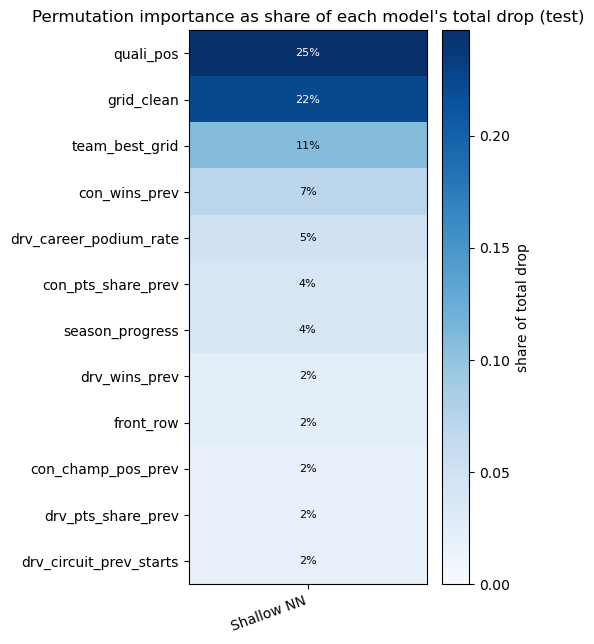

Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):


,Shallow NN
Shallow NN,1.0


In [11]:
CROSS = {}
t0 = time.time()
for key, m in MODELS.items():
    CROSS[key] = PI["test"] if key == EXPLAIN_KEY else perm_importance(m, test, n_repeats=N_REPEATS_CROSS)
print(f"cross-model permutation importance in {time.time()-t0:.0f}s")
cross_mat = pd.DataFrame({LABEL[k]: v.set_index("feature")["pr_auc_drop"] for k, v in CROSS.items()}).loc[FEATURES]
top_feats = cross_mat.mean(axis=1).sort_values(ascending=False).head(12).index.tolist()
share = cross_mat / cross_mat.clip(lower=0).sum()          # each model's importances as a share of its own total drop
fig, ax = plt.subplots(figsize=(1.3 * len(cross_mat.columns) + 4, 0.42 * len(top_feats) + 1.5))
im = ax.imshow(share.loc[top_feats].to_numpy(), cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels(share.columns, rotation=20, ha="right"); ax.set_yticks(range(len(top_feats))); ax.set_yticklabels(top_feats)
for (i, j), v in np.ndenumerate(share.loc[top_feats].to_numpy()): ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > share.loc[top_feats].to_numpy().max() * 0.6 else "black")
ax.set_title("Permutation importance as share of each model's total drop (test)"); plt.colorbar(im, label="share of total drop"); fig.tight_layout()
save_fig(fig, "perm_importance_cross_model.png")

cols_ = list(cross_mat.columns)
rank_corr = pd.DataFrame([[agreement(cross_mat[a], cross_mat[b_])["spearman_top"] for b_ in cols_] for a in cols_], index=cols_, columns=cols_)
print("Pairwise rank agreement of the permutation importances (Spearman over the union of each pair's top-10 features):")
display(rank_corr.round(2))
others = [c for c in rank_corr.columns if c != LABEL[EXPLAIN_KEY]]
if others:
    print(f"{LABEL[EXPLAIN_KEY]} vs the other models: " + ", ".join(f"{c} {rank_corr.loc[LABEL[EXPLAIN_KEY], c]:.2f} (top-10 overlap {agreement(cross_mat[LABEL[EXPLAIN_KEY]], cross_mat[c])['overlap_top']})" for c in others))

## 15.4 Does the explanation depend on the random seed of the network?

A network started from a different random seed can reach a similar score through different internal weights. The neural-network notebook saw validation PR-AUC move between seeds, so the explanation could also move. The saved network is retrained with three seeds using the identical recipe (train rows only, early stopping on validation), and the permutation importance rankings are compared. High rank agreement means the explanation is a property of the data and features; low agreement means the explanation of one network should be reported with that caveat. This section only runs when the explained model is the shallow network.

3 retrained networks in 27s


,seed,val_pr_auc,test_pr_auc
0,42,0.7479,0.6888
1,43,0.7363,0.6795
2,44,0.7340,0.6874


Reproduction check: retraining with seed 42 gives validation PR-AUC 0.7479; the saved model's is 0.7479 (identical).


,pair,spearman_all,spearman_top,overlap_top,k,n_union
0,seed 42 vs seed 43,0.57,0.61,7,10,13
1,seed 42 vs seed 44,0.46,0.43,7,10,13
2,seed 42 vs saved model,1.00,1.00,10,10,10
3,seed 43 vs seed 44,0.32,0.44,6,10,14
4,seed 43 vs saved model,0.57,0.61,7,10,13
5,seed 44 vs saved model,0.46,0.43,7,10,13


Top-5 features per run: {'seed 42': ['con_wins_prev', 'drv_career_podium_rate', 'grid_clean', 'quali_pos', 'team_best_grid'], 'seed 43': ['con_wins_prev', 'front_row', 'grid_clean', 'quali_pos', 'team_best_grid'], 'seed 44': ['con_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid', 'team_podium_rate_w10'], 'saved model': ['con_wins_prev', 'drv_career_podium_rate', 'grid_clean', 'quali_pos', 'team_best_grid']}
Features in the top 5 of every run: ['grid_clean', 'quali_pos', 'team_best_grid'] (3 of 5)
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_importance_seeds.png


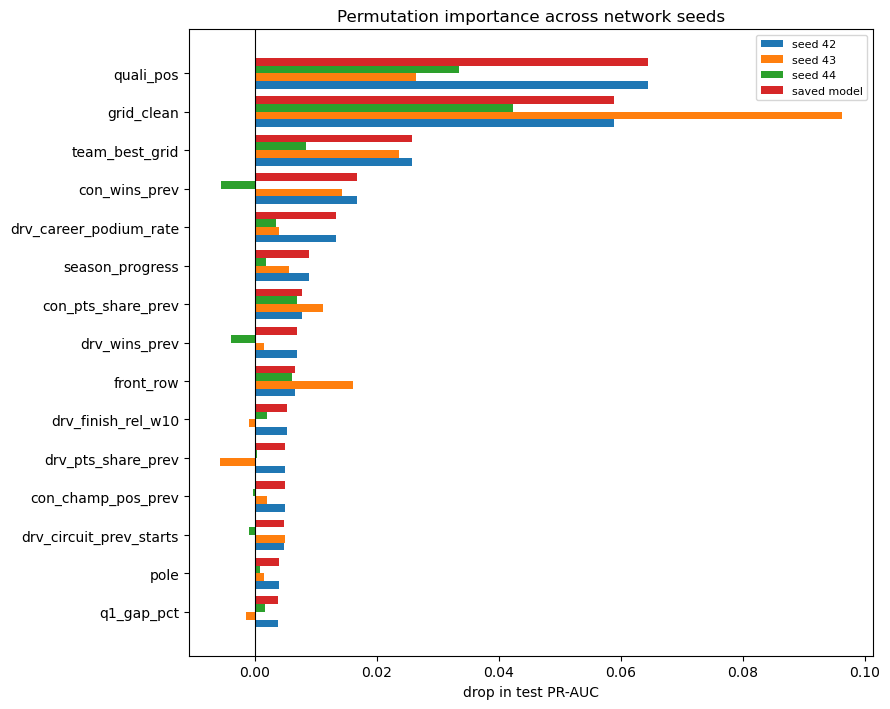

In [12]:
SEED_RANK, SEED_AGREE = None, None
if RUN_SEED_CHECK and EXPLAIN_KEY == "nn":
    prm = META["nn"]["params"]; seed_pi, seed_rows = {}, []
    t0 = time.time()
    for s in [SEED, SEED + 1, SEED + 2]:
        net_s, best_val = train_nn_pipeline(hidden=tuple(prm["hidden"]), alpha=prm["alpha"], lr=prm.get("lr", 1e-3), seed=s)
        seed_pi[s] = perm_importance(net_s, test, n_repeats=N_REPEATS_CROSS)
        seed_rows.append(dict(seed=s, val_pr_auc=best_val, test_pr_auc=average_precision_score(test[TARGET], predict_p(net_s, test))))
    saved_pi = perm_importance(model, test, n_repeats=N_REPEATS_CROSS)     # same number of repeats as the retrained runs
    print(f"3 retrained networks in {time.time()-t0:.0f}s")
    display(pd.DataFrame(seed_rows).round(4))
    saved_val = META["nn"].get("val", {}).get("pr_auc")
    if saved_val is not None:
        print(f"Reproduction check: retraining with seed {SEED} gives validation PR-AUC {seed_rows[0]['val_pr_auc']:.4f}; the saved model's is {saved_val:.4f} "
              f"({'identical' if abs(seed_rows[0]['val_pr_auc'] - saved_val) < 1e-4 else 'different: library versions or row order differ from the training environment'}).")
    SEED_RANK = pd.DataFrame({f"seed {s}": v.set_index("feature")["pr_auc_drop"] for s, v in seed_pi.items()})
    SEED_RANK["saved model"] = saved_pi.set_index("feature")["pr_auc_drop"]
    pair_rows = [dict(pair=f"{a} vs {b_}", **agreement(SEED_RANK[a], SEED_RANK[b_])) for a, b_ in itertools.combinations(SEED_RANK.columns, 2)]
    SEED_AGREE = pd.DataFrame(pair_rows); display(SEED_AGREE.round(2))
    tops = {c: set(SEED_RANK[c].sort_values(ascending=False).head(5).index) for c in SEED_RANK.columns}
    common = set.intersection(*tops.values())
    print("Top-5 features per run:", {c: sorted(v) for c, v in tops.items()})
    print(f"Features in the top 5 of every run: {sorted(common)} ({len(common)} of 5)")
    fig, ax = plt.subplots(figsize=(9, 0.38 * TOP_K + 1.5)); order = SEED_RANK["saved model"].sort_values(ascending=False).head(TOP_K).index[::-1]
    cols = list(SEED_RANK.columns); h = 0.8 / len(cols)
    for j, c in enumerate(cols): ax.barh(np.arange(len(order)) + (j - (len(cols) - 1) / 2) * h, SEED_RANK.loc[order, c], h, label=c)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.axvline(0, color="k", lw=0.8); ax.legend(fontsize=8)
    ax.set_xlabel("drop in test PR-AUC"); ax.set_title("Permutation importance across network seeds"); fig.tight_layout(); save_fig(fig, "perm_importance_seeds.png")
else:
    print("Seed check skipped (RUN_SEED_CHECK is off or the explained model is not the shallow network).")

## 15.5 Global explanation 2: SHAP

SHAP assigns each feature a signed contribution to every single prediction, such that **reference average + sum of contributions = the model's score for that row** (checked numerically below). Averaging the absolute contributions over rows gives a global importance; plotting the signed contributions against the feature value shows the direction and shape of the model's reliance.

The model is a neural network behind a preprocessing pipeline, so the model-agnostic **permutation explainer** is used, applied to the *raw 29 features* (the pipeline's imputation and missing indicators are part of the function being explained). It is run on every test row, with 100 hybrid-era training rows as the reference.

In [13]:
# ---- reference data, explainer and SHAP values for every test row ------------------------------------------------
bg_pool = train[train["year"] >= BACKGROUND_FROM_YEAR]
if len(bg_pool) < 300:
    print(f"only {len(bg_pool)} training rows from {BACKGROUND_FROM_YEAR}; using validation rows as the reference instead"); bg_pool = val
bg_df = bg_pool.sample(min(BACKGROUND_SIZE, len(bg_pool)), random_state=SEED)[FEATURES]
bg_arr = bg_df.to_numpy(float)
print(f"reference data: {len(bg_df)} rows sampled from {len(bg_pool):,} training rows of seasons {int(bg_pool['year'].min())}-{int(bg_pool['year'].max())}")

def xai_proba(X): return model.predict_proba(pd.DataFrame(X, columns=FEATURES))
def xai_f(X): return xai_proba(X)[:, 1]

ex = (test if N_EXPLAIN is None else test.sample(min(N_EXPLAIN, len(test)), random_state=SEED)).reset_index(drop=True)
X_ex = ex[FEATURES].to_numpy(float)

def run_shap(bg, X, n_perm=N_PERMUTATIONS):
    masker = shap.maskers.Independent(bg, max_samples=len(bg))
    explainer = shap.explainers.Permutation(xai_f, masker, feature_names=FEATURES, seed=SEED)
    return explainer(X, max_evals=2 * len(FEATURES) * n_perm + 1, silent=True)

t0 = time.time()
sv = run_shap(bg_arr, X_ex)
sv.feature_names = list(FEATURES)
p_ex = xai_f(X_ex)
add_err = float(np.abs(sv.values.sum(1) + sv.base_values - p_ex).max())
print(f"SHAP for {len(ex):,} rows x {len(FEATURES)} features in {time.time()-t0:.0f}s")
print(f"additivity check, max |base + sum(SHAP) - model score| = {add_err:.2e}")
assert add_err < 1e-6, "SHAP values do not add up to the model output"
base_val = float(np.mean(sv.base_values))
print(f"reference average score (SHAP base value) = {base_val:.3f}  vs true podium rate in test = {ex[TARGET].mean():.3f} "
      f"(the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)")

shap_tab = pd.DataFrame({"feature": FEATURES, "group": [group_of[f] for f in FEATURES],
                         "mean_abs_shap": np.abs(sv.values).mean(0), "mean_shap": sv.values.mean(0)}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_tab["share_of_total"] = shap_tab["mean_abs_shap"] / shap_tab["mean_abs_shap"].sum()
display(shap_tab.head(TOP_K).round(4))

reference data: 100 rows sampled from 2,470 training rows of seasons 2014-2019
SHAP for 1,351 rows x 29 features in 85s
additivity check, max |base + sum(SHAP) - model score| = 4.89e-10
reference average score (SHAP base value) = 0.346  vs true podium rate in test = 0.151 (the model is trained with up-weighted podiums, so its scores average above the true rate: scores are for ranking, not calibrated probabilities)


,feature,group,mean_abs_shap,mean_shap,share_of_total
0,grid_clean,grid,0.0595,-0.0128,0.1085
1,quali_pos,qualifying,0.0591,-0.0131,0.1078
2,team_best_grid,grid,0.0477,-0.0066,0.0870
3,drv_pts_share_prev,standings,0.0334,-0.0031,0.0609
4,drv_podium_rate_w10,driver_form,0.0322,-0.0037,0.0588
5,quali_gap_pct,qualifying,0.0281,0.0132,0.0512
6,drv_career_podium_rate,driver_form,0.0270,-0.0064,0.0492
7,con_wins_prev,standings,0.0259,-0.0051,0.0473
8,drv_champ_pos_prev,standings,0.0231,-0.0004,0.0422
9,team_podium_rate_w10,constructor_form,0.0226,-0.0032,0.0412


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_bar.png


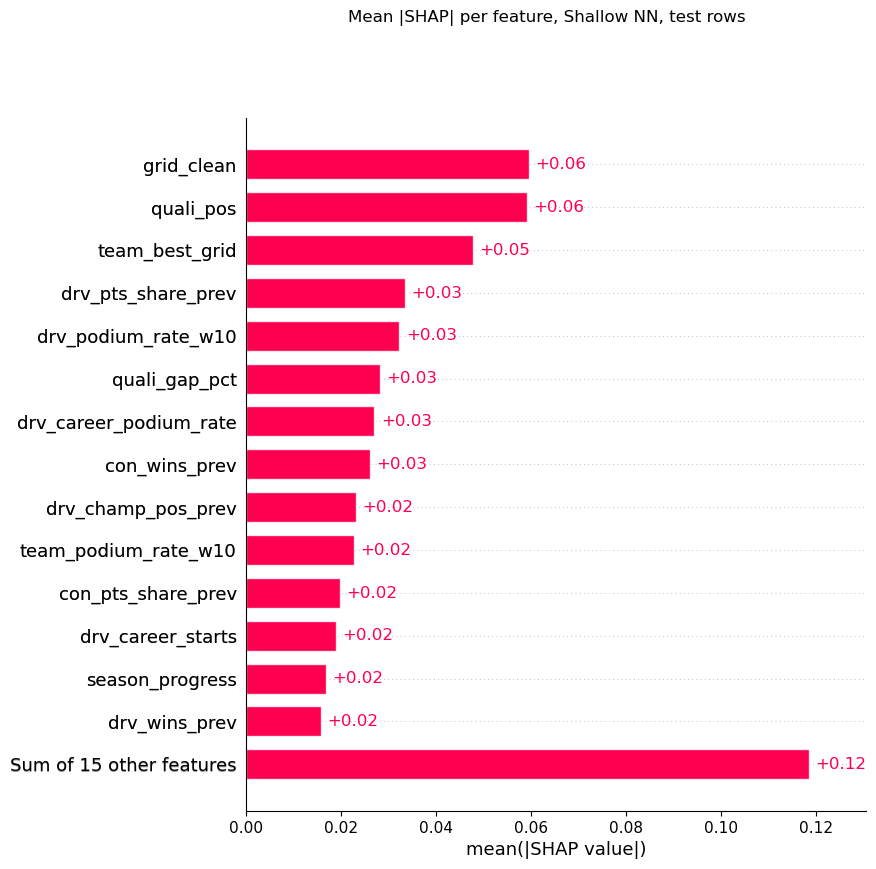

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_beeswarm.png


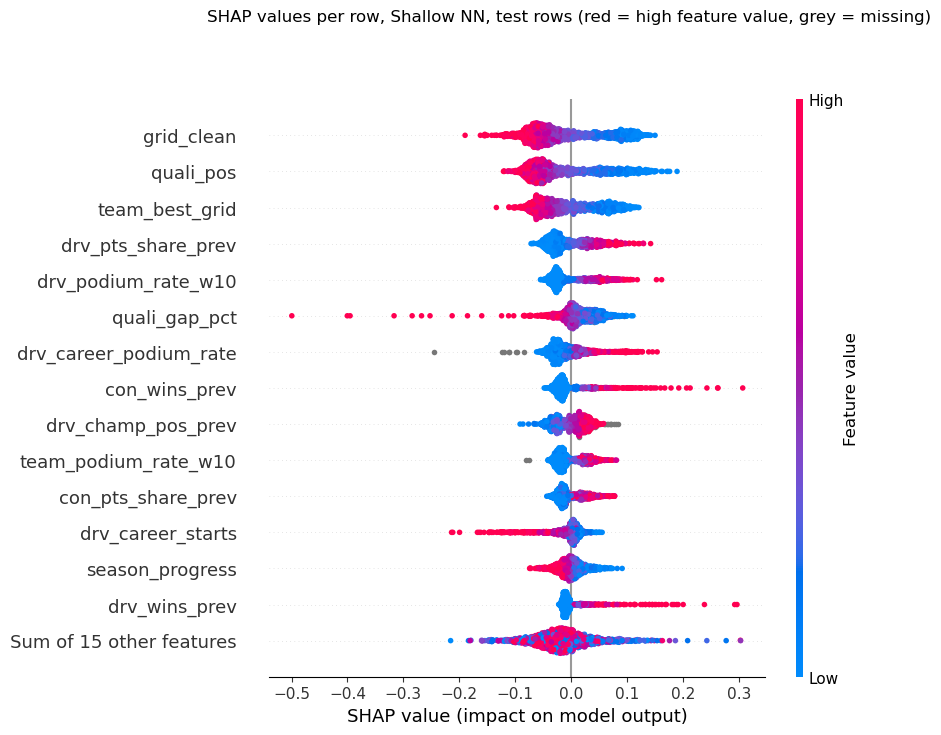

In [14]:
# bar (mean |SHAP|) and beeswarm (signed SHAP coloured by feature value; grey = missing value)
plt.figure(); shap.plots.bar(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"Mean |SHAP| per feature, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); save_fig(fig, "shap_bar.png")
plt.figure(); shap.plots.beeswarm(sv, max_display=TOP_K, show=False); fig = plt.gcf()
fig.suptitle(f"SHAP values per row, {LABEL[EXPLAIN_KEY]}, test rows (red = high feature value, grey = missing)", y=1.0); save_fig(fig, "shap_beeswarm.png")

### 15.5.1 Group SHAP

SHAP values are additive, so the contribution of a feature group to a row is simply the sum of its members' values. This is immune to the credit-splitting problem between correlated features inside a group, and it matches the grouping used by the ablation.

,group,n_features,mean_abs_group_shap,mean_signed,share_of_total
0,grid,6,0.1119,-0.0222,0.2922
1,qualifying,4,0.0755,-0.0083,0.1972
2,standings,6,0.0671,-0.0130,0.1754
3,driver_form,4,0.0525,-0.0158,0.1370
4,constructor_form,2,0.0367,-0.0043,0.0959
5,context,4,0.0210,-0.0022,0.0548
6,circuit_history,3,0.0182,-0.0026,0.0475


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_groups.png


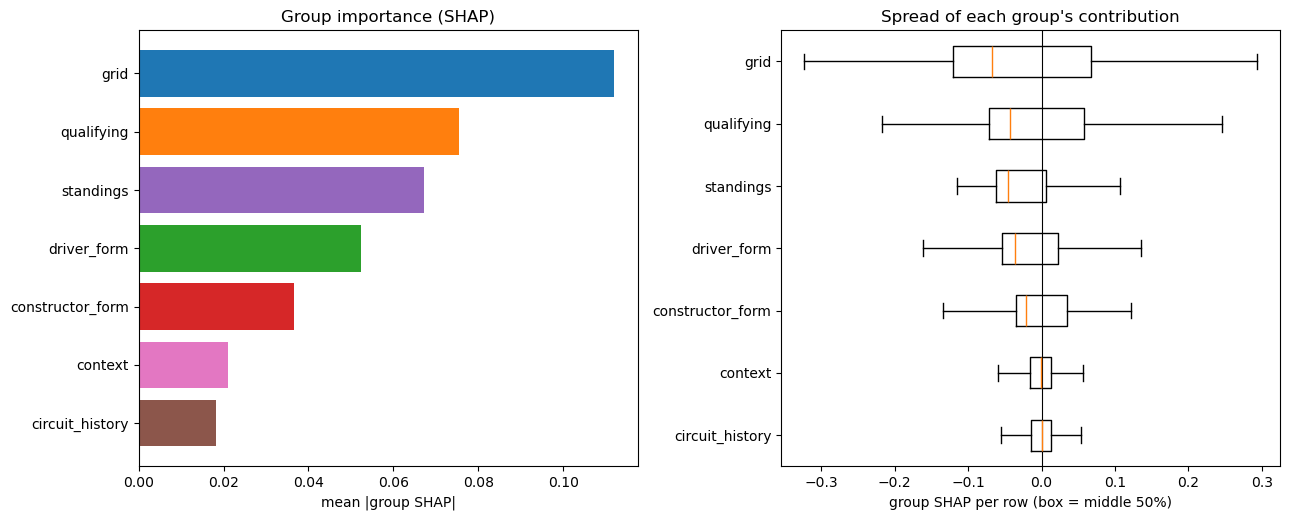

In [15]:
gidx = {g: [FEATURES.index(f) for f in fs] for g, fs in FEATURE_GROUPS.items()}
G = pd.DataFrame({g: sv.values[:, ix].sum(1) for g, ix in gidx.items()})
group_shap = pd.DataFrame({"group": list(G.columns), "n_features": [len(FEATURE_GROUPS[g]) for g in G.columns],
                           "mean_abs_group_shap": G.abs().mean().values, "mean_signed": G.mean().values}).sort_values("mean_abs_group_shap", ascending=False).reset_index(drop=True)
group_shap["share_of_total"] = group_shap["mean_abs_group_shap"] / group_shap["mean_abs_group_shap"].sum()
display(group_shap.round(4))
order = group_shap.sort_values("mean_abs_group_shap")["group"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.5 * len(order) + 1.8))
axes[0].barh(order, group_shap.set_index("group").loc[order, "mean_abs_group_shap"], color=[group_colors[g] for g in order])
axes[0].set_xlabel("mean |group SHAP|"); axes[0].set_title("Group importance (SHAP)")
try: axes[1].boxplot([G[g] for g in order], vert=False, tick_labels=order, showfliers=False)
except TypeError: axes[1].boxplot([G[g] for g in order], vert=False, labels=order, showfliers=False)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("group SHAP per row (box = middle 50%)"); axes[1].set_title("Spread of each group's contribution")
fig.tight_layout(); save_fig(fig, "shap_groups.png")

### 15.5.2 Dependence plots for the four most important features

Each dot is one test row. The vertical axis is how much the feature moved that row's score; colour is the feature that interacts most with it (chosen automatically). These show the *shape* of the model's reliance, for example whether the effect of the starting slot is a smooth decline or a cliff after the front rows. They describe the model, not the sport.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_dependence_top4.png


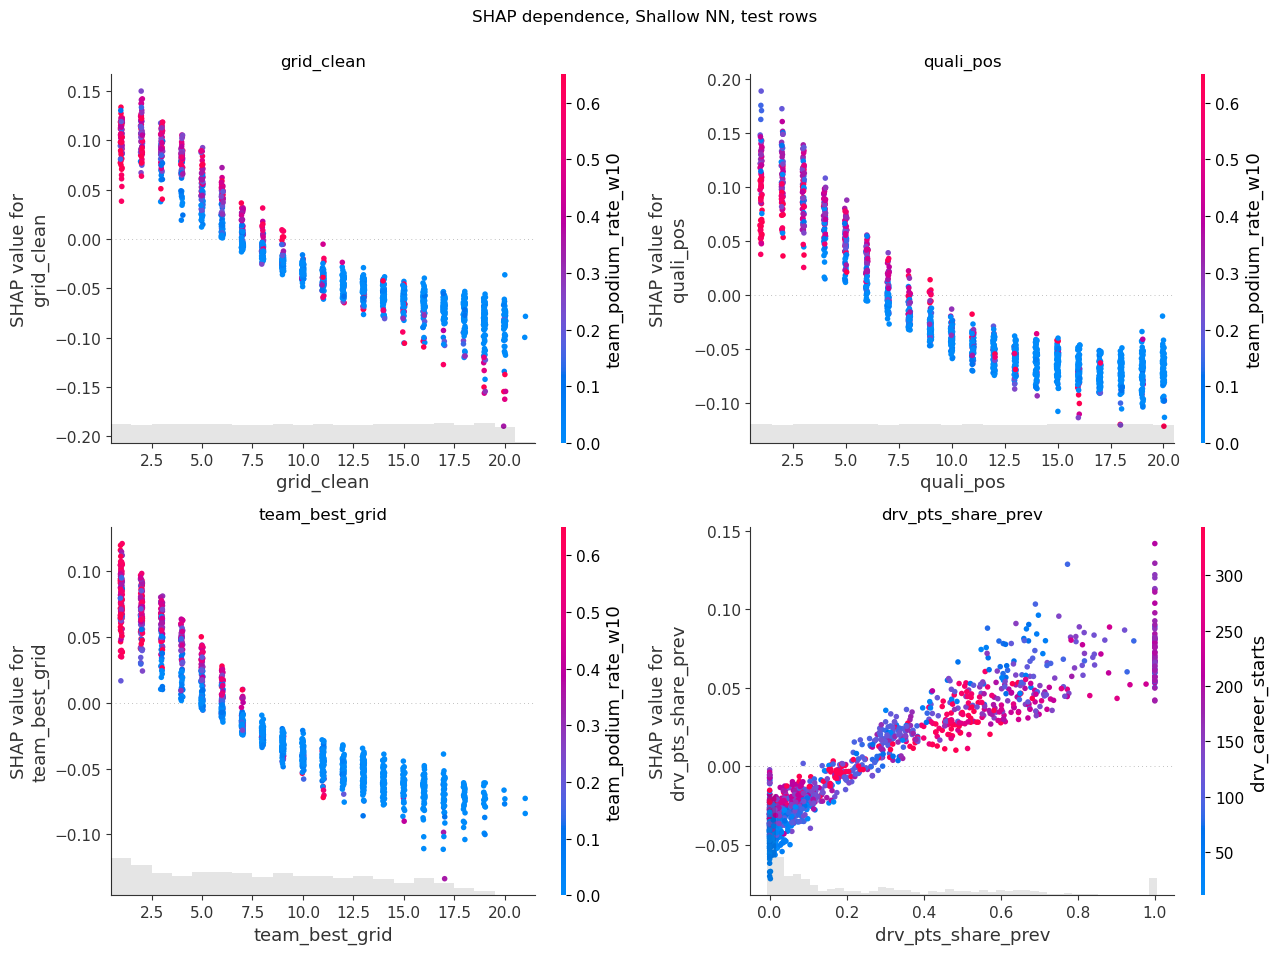

In [16]:
top4 = shap_tab.head(4)["feature"].tolist()
try:
    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
    for ax, f in zip(axes.ravel(), top4):
        shap.plots.scatter(sv[:, f], color=sv, ax=ax, show=False); ax.set_title(f)
    fig.suptitle(f"SHAP dependence, {LABEL[EXPLAIN_KEY]}, test rows", y=1.0); fig.tight_layout(); save_fig(fig, "shap_dependence_top4.png")
except TypeError:      # older shap versions have no ax= argument: one figure per feature
    plt.close("all")
    for f in top4:
        plt.figure(); shap.plots.scatter(sv[:, f], color=sv, show=False); save_fig(plt.gcf(), f"shap_dependence_{f}.png")

### 15.5.3 Do permutation importance and SHAP tell the same story?

They measure different things: permutation importance is the **loss in performance** from destroying a feature; mean |SHAP| is the **average size of the feature's push** on predictions, whether or not the push is right. A feature can move scores a lot and still add little accuracy (a noisy feature the model leans on), so disagreement is informative, not an error.

Permutation vs SHAP: Spearman over all 29 features 0.59 | over the top-10 union (15 features) 0.36 | top-10 overlap 5 of 10 | top-5 shared: ['grid_clean', 'quali_pos', 'team_best_grid']


,perm_pr_auc_drop,mean_abs_shap,perm_rank,shap_rank,rank_gap
feature,,,,,
grid_clean,0.0642,0.0595,2,1,1
quali_pos,0.0709,0.0591,1,2,-1
team_best_grid,0.0309,0.0477,3,3,0
drv_pts_share_prev,0.0055,0.0334,11,4,7
drv_podium_rate_w10,0.0040,0.0322,15,5,10
quali_gap_pct,0.0013,0.0281,22,6,16
drv_career_podium_rate,0.0141,0.0270,5,7,-2
con_wins_prev,0.0202,0.0259,4,8,-4
drv_champ_pos_prev,-0.0005,0.0231,26,9,17


Features whose two ranks differ by 8 places or more: {'front_row': (9, 22), 'grid_minus_quali': (13, 25), 'con_champ_pos_prev': (10, 20), 'pole': (17, 26), 'team_podium_rate_w10': (20, 10), 'drv_podium_rate_w10': (15, 5), 'quali_gap_pct': (22, 6), 'drv_champ_pos_prev': (26, 9)}
Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\perm_vs_shap.png


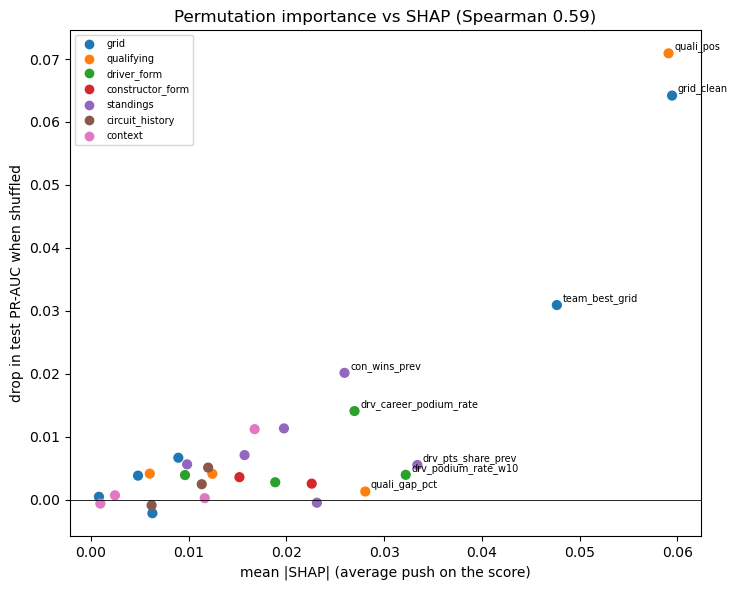

In [17]:
cmp = pd.DataFrame({"perm_pr_auc_drop": PI["test"].set_index("feature")["pr_auc_drop"],
                    "mean_abs_shap": shap_tab.set_index("feature")["mean_abs_shap"]}).loc[FEATURES]
cmp["perm_rank"] = cmp["perm_pr_auc_drop"].rank(ascending=False, method="min").astype(int)
cmp["shap_rank"] = cmp["mean_abs_shap"].rank(ascending=False, method="min").astype(int)
cmp["rank_gap"] = cmp["perm_rank"] - cmp["shap_rank"]
AG_PS = agreement(cmp["perm_pr_auc_drop"], cmp["mean_abs_shap"]); rho_ps = AG_PS["spearman_all"]
tp, ts = (set(cmp.sort_values(c_, ascending=True).head(5).index) for c_ in ("perm_rank", "shap_rank"))
print(f"Permutation vs SHAP: Spearman over all {len(cmp)} features {AG_PS['spearman_all']:.2f} | over the top-10 union ({AG_PS['n_union']} features) {AG_PS['spearman_top']:.2f} | "
      f"top-10 overlap {AG_PS['overlap_top']} of 10 | top-5 shared: {sorted(tp & ts)}")
display(cmp.sort_values("shap_rank").head(TOP_K).round(4))
big_gap = cmp[cmp["rank_gap"].abs() >= 8].sort_values("rank_gap")
print("Features whose two ranks differ by 8 places or more:", {f: (int(r.perm_rank), int(r.shap_rank)) for f, r in big_gap.iterrows()} or "none")

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(cmp["mean_abs_shap"], cmp["perm_pr_auc_drop"], c=[group_colors[group_of[f]] for f in cmp.index], s=40)
for f in cmp.sort_values("shap_rank").head(8).index: ax.annotate(f, (cmp.loc[f, "mean_abs_shap"], cmp.loc[f, "perm_pr_auc_drop"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("mean |SHAP| (average push on the score)"); ax.set_ylabel("drop in test PR-AUC when shuffled")
ax.set_title(f"Permutation importance vs SHAP (Spearman {rho_ps:.2f})")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in group_colors.items()], fontsize=7); fig.tight_layout(); save_fig(fig, "perm_vs_shap.png")

## 15.6 Sensitivity checks

### 15.6.1 How much does the SHAP reference data matter?

The same explanation is recomputed on a random 300-row subset of the test rows with three different reference samples: the default (hybrid-era training rows), a random sample of **all** training eras, and the validation rows. If the importance ranking barely moves, the reference choice is not driving the conclusions; the base value will move, because it is the average score of the reference.

In [18]:
sub_pos = np.random.default_rng(SEED).choice(len(ex), size=min(300, len(ex)), replace=False)
X_sub = X_ex[sub_pos]
BG = {"hybrid-era train (default)": bg_arr,
      "all-era train (random)": train.sample(min(BACKGROUND_SIZE, len(train)), random_state=SEED)[FEATURES].to_numpy(float),
      "validation": val.sample(min(BACKGROUND_SIZE, len(val)), random_state=SEED)[FEATURES].to_numpy(float)}
bg_imp, bg_base = {}, {}
t0 = time.time()
for name, b in BG.items():
    s_ = run_shap(b, X_sub); bg_imp[name] = np.abs(s_.values).mean(0); bg_base[name] = float(s_.base_values.mean())
print(f"3 reference choices on {len(X_sub)} rows in {time.time()-t0:.0f}s")
bg_imp = pd.DataFrame(bg_imp, index=FEATURES)
display(pd.Series(bg_base, name="base value (average score of the reference)").round(3).to_frame())
display(bg_imp.corr(method="spearman").round(3))
bg_tops = {c: set(bg_imp[c].sort_values(ascending=False).head(5).index) for c in bg_imp.columns}
print("Top-5 features per reference:", {c: sorted(v) for c, v in bg_tops.items()})
print(f"In the top 5 under every reference: {sorted(set.intersection(*bg_tops.values()))}")
BG_MIN_RHO = float(bg_imp.corr(method="spearman").to_numpy()[np.triu_indices(len(BG), 1)].min())

3 reference choices on 300 rows in 52s


,base value (average score of the reference)
hybrid-era train (default),0.346
all-era train (random),0.314
validation,0.249


,hybrid-era train (default),all-era train (random),validation
hybrid-era train (default),1.000,0.858,0.979
all-era train (random),0.858,1.000,0.863
validation,0.979,0.863,1.000


Top-5 features per reference: {'hybrid-era train (default)': ['drv_podium_rate_w10', 'drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid'], 'all-era train (random)': ['drv_pts_share_prev', 'grid_clean', 'q1_gap_pct', 'quali_pos', 'team_best_grid'], 'validation': ['drv_podium_rate_w10', 'drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid']}
In the top 5 under every reference: ['drv_pts_share_prev', 'grid_clean', 'quali_pos', 'team_best_grid']


### 15.6.2 Independent cross-check: TreeSHAP on XGBoost

XGBoost was trained on the same rows and features and scores almost the same as the final model on the test seasons. Its SHAP values come from an exact tree algorithm (no sampling, no reference-data choice in the default mode) and are expressed in **log-odds**, so only the *ranking and shape* are comparable with the network's, not the magnitudes. If both models lean on the same features, the story is about the data. Differences point to model-specific behaviour.

In [19]:
XGB_SHAP, AG_X = None, None
if RUN_XGB_CROSSCHECK and "xgb" in MODELS:
    try:
        xp = MODELS["xgb"]; Xt = xp.named_steps["pre"].transform(ex[FEATURES])
        try: cols_x = list(xp.named_steps["pre"].get_feature_names_out())
        except Exception: cols_x = CONTINUOUS + BINARY
        xv = np.asarray(shap.TreeExplainer(xp.named_steps["clf"]).shap_values(np.asarray(Xt, float)))
        if xv.ndim == 3: xv = xv[..., 1]
        XGB_SHAP = pd.DataFrame(xv, columns=cols_x)[FEATURES]
    except Exception as e:
        print("TreeSHAP on XGBoost failed (usually a shap/xgboost version mismatch), skipping:", type(e).__name__, str(e)[:200])
if XGB_SHAP is not None:
    xgb_tab = pd.DataFrame({"mean_abs_shap_xgb": XGB_SHAP.abs().mean(), "mean_abs_shap_main": pd.Series(np.abs(sv.values).mean(0), index=FEATURES)})
    AG_X = agreement(xgb_tab["mean_abs_shap_main"], xgb_tab["mean_abs_shap_xgb"]); rho_x = AG_X["spearman_all"]
    tx, tm = (set(xgb_tab[c_].sort_values(ascending=False).head(5).index) for c_ in xgb_tab.columns)
    print(f"Mean |SHAP|, XGBoost vs {LABEL[EXPLAIN_KEY]}: Spearman over all features {AG_X['spearman_all']:.2f} | top-10 union {AG_X['spearman_top']:.2f} | top-10 overlap {AG_X['overlap_top']} of 10 | top-5 shared {sorted(tx & tm)}")
    shares = xgb_tab / xgb_tab.sum(); order = shares.sum(axis=1).sort_values(ascending=False).head(12).index[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.5)); h = 0.38
    ax.barh(np.arange(len(order)) - h / 2, shares.loc[order, "mean_abs_shap_main"], h, label=f"{LABEL[EXPLAIN_KEY]} (permutation SHAP)")
    ax.barh(np.arange(len(order)) + h / 2, shares.loc[order, "mean_abs_shap_xgb"], h, label="XGBoost (TreeSHAP)")
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel("share of the model's total mean |SHAP|"); ax.legend(fontsize=8)
    ax.set_title("Same features, two models"); fig.tight_layout(); save_fig(fig, "shap_nn_vs_xgb.png")
    plt.figure(); shap.plots.beeswarm(shap.Explanation(values=XGB_SHAP.to_numpy(), data=X_ex, feature_names=FEATURES), max_display=TOP_K, show=False)
    fig = plt.gcf(); fig.suptitle("XGBoost TreeSHAP (log-odds), test rows", y=1.0); save_fig(fig, "shap_beeswarm_xgb.png")
else:
    print("XGBoost cross-check not run.")

XGBoost cross-check not run.


## 15.7 Local explanations

Global importance averages over thousands of rows. A local explanation answers "why did the model give *this* driver in *this* race that score?". Four test rows are picked by fixed rules (not by hand), so the selection cannot be accused of cherry-picking flattering cases:

| Case | Rule |
|---|---|
| Confident hit | podium finisher with the highest score (and above the threshold) |
| Missed podium | podium finisher with the lowest score (largest miss) |
| False alarm | non-podium driver with the highest score (largest false alarm) |
| Borderline | the row whose score is closest to the decision threshold |

Each is explained with **local SHAP** (waterfall) and **LIME**. The finishing position and status shown in the table are post-race facts shown only to describe the case; they are never inputs.

In [20]:
thr = THRESHOLD[EXPLAIN_KEY]; y_ex = ex[TARGET].to_numpy()
def pick(mask, how):
    ix = np.where(mask)[0]
    return None if len(ix) == 0 else int(ix[np.argmax(p_ex[ix])] if how == "max" else ix[np.argmin(p_ex[ix])])
CASES = {"Confident hit": pick((y_ex == 1) & (p_ex >= thr), "max"), "Missed podium": pick((y_ex == 1) & (p_ex < thr), "min"),
         "False alarm": pick((y_ex == 0) & (p_ex >= thr), "max"), "Borderline": int(np.argmin(np.abs(p_ex - thr)))}
CASES = {k: v for k, v in CASES.items() if v is not None}

def load_clean(name):
    p = locate(f"{name}.parquet")
    try: return pd.read_parquet(p) if p else None
    except Exception: return None
drivers_t, races_t, cons_t, results_t, status_t = (load_clean(n) for n in ["drivers", "races", "constructors", "results", "status"])
def mapping(t, key, fn):
    if t is None or key not in t.columns: return {}
    return {int(k): v for k, v in zip(pd.to_numeric(t[key], errors="coerce"), t.apply(fn, axis=1)) if not pd.isna(k)}
drv_name = mapping(drivers_t, "driverId", lambda r: f"{r['forename']} {r['surname']}") if drivers_t is not None and "forename" in drivers_t else {}
race_name = mapping(races_t, "raceId", lambda r: f"{int(r['year'])} {r['name']}") if races_t is not None and "name" in races_t else {}
con_name = mapping(cons_t, "constructorId", lambda r: r["name"]) if cons_t is not None and "name" in cons_t else {}
res_info = {}
if results_t is not None and {"resultId", "positionOrder"} <= set(results_t.columns):
    st = {} if status_t is None else dict(zip(pd.to_numeric(status_t["statusId"]), status_t["status"]))
    for r in results_t.itertuples():
        res_info[int(r.resultId)] = (r.positionOrder, st.get(int(r.statusId)) if hasattr(r, "statusId") and not pd.isna(r.statusId) else None)

def case_label(i):
    r = ex.iloc[i]
    return (f"{drv_name.get(int(r['driverId']), 'driver ' + str(int(r['driverId'])))}, "
            f"{race_name.get(int(r['raceId']), 'race ' + str(int(r['raceId'])))}, {con_name.get(int(r['constructorId']), 'team ' + str(int(r['constructorId'])))}")

rows = []
for name, i in CASES.items():
    r = ex.iloc[i]; fin = res_info.get(int(r["resultId"]), (None, None))
    rows.append(dict(case=name, row=case_label(i), score=round(float(p_ex[i]), 3), threshold=round(thr, 3), predicted_podium=bool(p_ex[i] >= thr),
                     actual_podium=int(r[TARGET]), grid=r["grid_clean"], quali_pos=r["quali_pos"],
                     finish_position=fin[0], race_status=fin[1], n_missing_features=int(ex.loc[i, FEATURES].isna().sum())))
case_df = pd.DataFrame(rows); display(case_df)

,case,row,score,threshold,predicted_podium,actual_podium,grid,quali_pos,finish_position,race_status,n_missing_features
0,Confident hit,"Max Verstappen, 2023 Abu Dhabi Grand Prix, Red...",0.995,0.738,True,1,1.0,1.0,1,Finished,0
1,Missed podium,"Sergio Pérez, 2023 Austrian Grand Prix, Red Bull",0.000,0.738,False,1,15.0,15.0,3,Finished,0
2,False alarm,"Max Verstappen, 2024 Austrian Grand Prix, Red ...",0.983,0.738,True,0,1.0,1.0,5,Finished,0
3,Borderline,"Carlos Sainz, 2023 Spanish Grand Prix, Ferrari",0.738,0.738,False,0,2.0,2.0,5,Finished,0


### 15.7.1 Local SHAP (waterfall)

Read each plot from the bottom: it starts at the reference average score `E[f(X)]`, each bar adds or subtracts the push of one feature (red up, blue down; the number in grey is that row's value of the feature), and the top value `f(x)` is the model's score for the row. The score is compared with the decision threshold printed in the title.

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_confident_hit.png


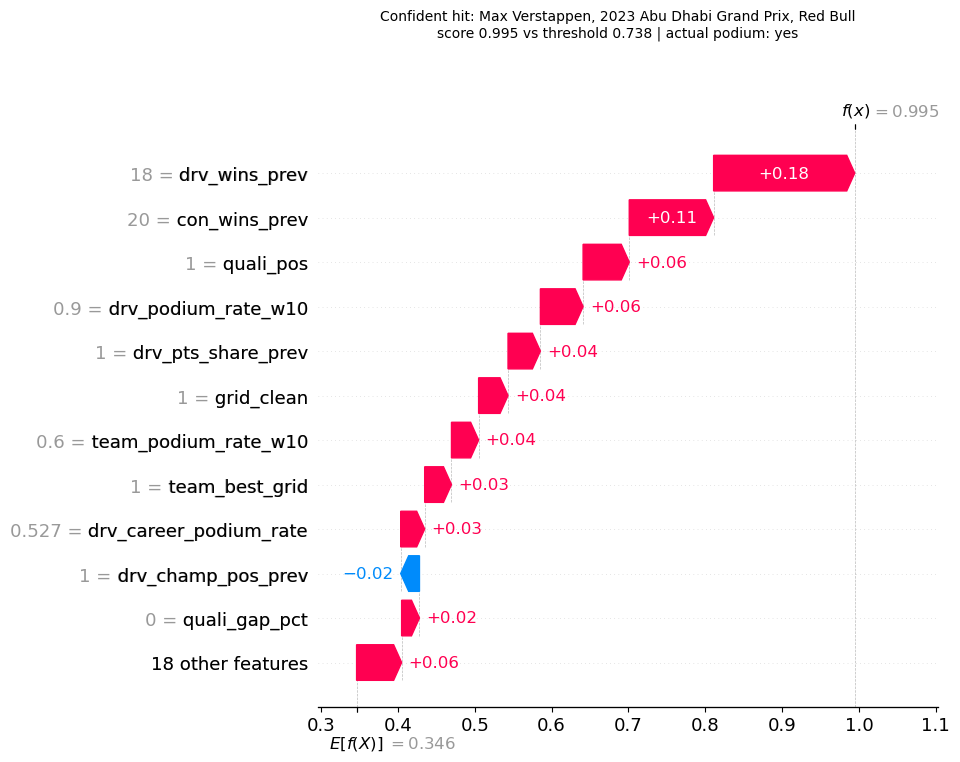

  Confident hit: pushed UP by drv_wins_prev (18: +0.184), con_wins_prev (20: +0.110), quali_pos (1: +0.060)
                 pushed DOWN by drv_champ_pos_prev (1: -0.024), con_champ_pos_prev (1: -0.012), season_progress (1: -0.012)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_missed_podium.png


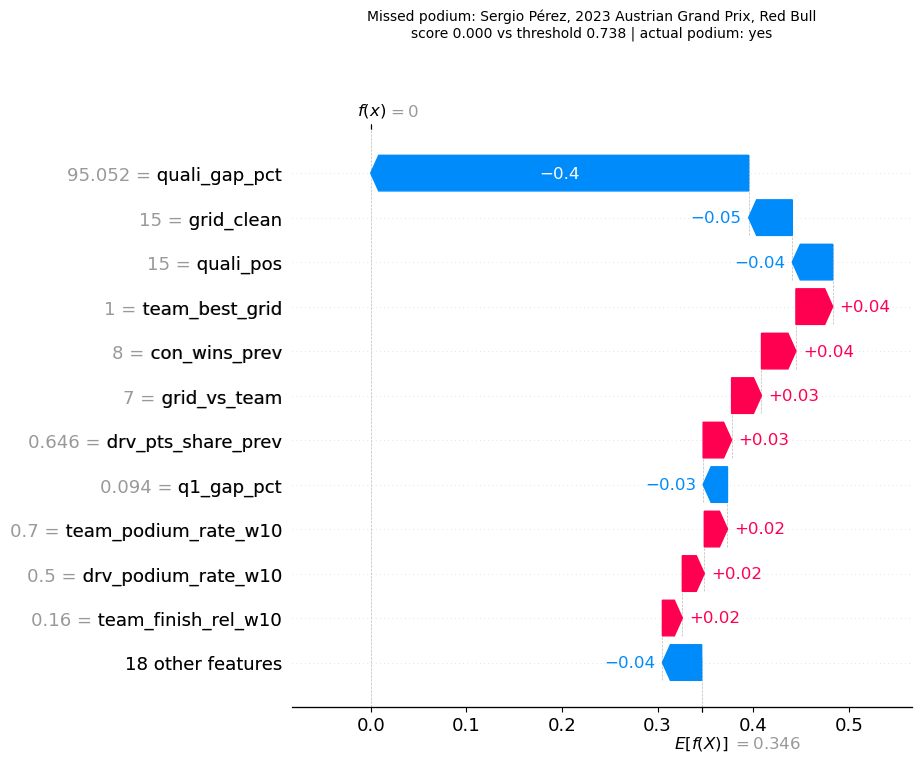

  Missed podium: pushed UP by team_best_grid (1: +0.038), con_wins_prev (8: +0.036), grid_vs_team (7: +0.031)
                 pushed DOWN by quali_gap_pct (95.1: -0.395), grid_clean (15: -0.046), quali_pos (15: -0.042)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_false_alarm.png


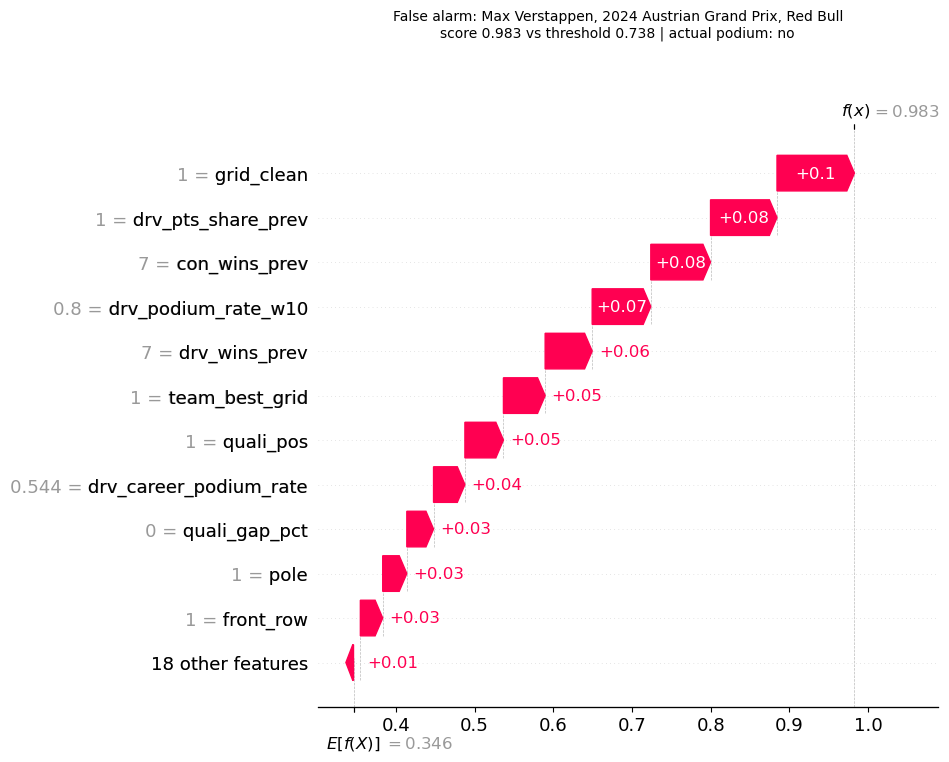

  False alarm: pushed UP by grid_clean (1: +0.098), drv_pts_share_prev (1: +0.084), con_wins_prev (7: +0.076)
               pushed DOWN by drv_champ_pos_prev (1: -0.026), con_champ_pos_prev (1: -0.023), drv_finish_rel_w10 (0.175: -0.011)

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\shap_waterfall_borderline.png


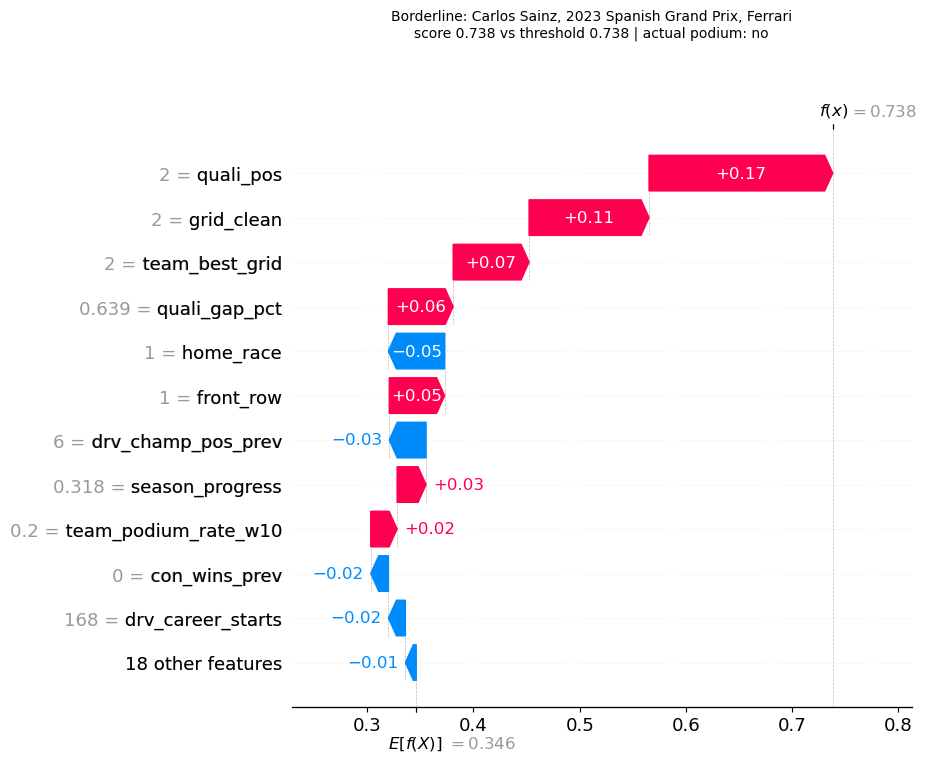

  Borderline: pushed UP by quali_pos (2: +0.173), grid_clean (2: +0.113), team_best_grid (2: +0.071)
              pushed DOWN by home_race (1: -0.053), drv_champ_pos_prev (6: -0.035), con_wins_prev (0: -0.017)



In [21]:
def shap_top(i, k=3):
    v = pd.Series(sv.values[i], index=FEATURES); pos = v.sort_values(ascending=False).head(k); neg = v.sort_values().head(k)
    fmt = lambda s: ", ".join(f"{f} ({ex.loc[i, f]:.3g}: {x:+.3f})" if not pd.isna(ex.loc[i, f]) else f"{f} (missing: {x:+.3f})" for f, x in s.items())
    return fmt(pos), fmt(neg)

for name, i in CASES.items():
    plt.figure(); shap.plots.waterfall(sv[i], max_display=12, show=False); fig = plt.gcf()
    fig.suptitle(f"{name}: {case_label(i)}\nscore {p_ex[i]:.3f} vs threshold {thr:.3f} | actual podium: {'yes' if y_ex[i] else 'no'}", y=1.04, fontsize=10)
    save_fig(fig, f"shap_waterfall_{name.lower().replace(' ', '_')}.png")
    up, down = shap_top(i)
    print(f"  {name}: pushed UP by {up}\n  {' ' * len(name)}  pushed DOWN by {down}\n")

### 15.7.2 LIME

LIME perturbs the row many times (here 5,000), asks the model to score the perturbed rows, and fits a small weighted linear model on *binned* feature values. Its weights say which bins of which features pushed *this* score up or down in the neighbourhood of the row.

Practical differences from SHAP that matter when comparing them:
- LIME cannot take missing values, so the few missing inputs are filled with the training median (binary flags: most frequent value) before it runs. For cases with missing features this slightly changes what is explained; the count is in the case table above.
- LIME is random. The stability check below reruns it with different seeds.
- LIME weights are relative to its own local model, not to the SHAP reference average, so only the **direction and ranking** are compared with SHAP, not the sizes.
- `R2` is the fit of LIME's local model to the network around the row. A low value means the network is not well approximated by a simple model there, and the LIME weights should be trusted less.

In [22]:
LIME_RES, LIME_CMP = {}, []
if HAVE_LIME:
    fill = pd.concat([train[CONTINUOUS].median(), train[BINARY].mode().iloc[0]])
    lime_bg = bg_pool[FEATURES].fillna(fill).to_numpy(float)
    cat_idx = [FEATURES.index(b) for b in BINARY]
    def lime_run(x, seed):
        le = LimeTabularExplainer(lime_bg, feature_names=FEATURES, categorical_features=cat_idx, class_names=["no podium", "podium"],
                                  mode="classification", discretize_continuous=True, random_state=seed)
        e = le.explain_instance(x, xai_proba, num_features=10, num_samples=LIME_SAMPLES, labels=(1,))
        sc = e.score; sc = sc.get(1) if isinstance(sc, dict) else sc
        return e, float(sc) if sc is not None else np.nan
    t0 = time.time()
    for name, i in CASES.items():
        x = ex.loc[i, FEATURES].fillna(fill).to_numpy(float)
        e, r2 = lime_run(x, SEED)
        m = e.as_map()[1]; desc = dict(zip([a for a, _ in m], [d for d, _ in e.as_list(label=1)]))
        lime_w = pd.Series({FEATURES[a]: w for a, w in m}); lime_desc = {FEATURES[a]: desc[a] for a, _ in m}
        # stability: top-5 features across different LIME seeds
        tops = [set(lime_w.abs().sort_values(ascending=False).head(5).index)]
        for s in range(1, LIME_SEEDS):
            ws = pd.Series({FEATURES[a]: w for a, w in lime_run(x, SEED + s)[0].as_map()[1]}); tops.append(set(ws.abs().sort_values(ascending=False).head(5).index))
        jac = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(tops, 2)])
        shap_v = pd.Series(sv.values[i], index=FEATURES)
        s_top5, l_top5 = set(shap_v.abs().sort_values(ascending=False).head(5).index), set(lime_w.abs().sort_values(ascending=False).head(5).index)
        common = lime_w.index
        LIME_RES[name] = dict(weights=lime_w, desc=lime_desc, r2=r2)
        LIME_CMP.append(dict(case=name, lime_local_R2=r2, top5_overlap_shap_lime=len(s_top5 & l_top5),
                             sign_agreement_on_lime_top10=float(np.mean(np.sign(lime_w[common]) == np.sign(shap_v[common]))),
                             spearman_signed_on_lime_top10=spearmanr(lime_w[common], shap_v[common]).statistic,
                             lime_top5_stability_jaccard=jac))
    print(f"LIME for {len(CASES)} cases x {LIME_SEEDS} seeds in {time.time()-t0:.0f}s")
    lime_cmp = pd.DataFrame(LIME_CMP); display(lime_cmp.round(3))
else:
    print("LIME not installed: skipped. (pip install lime)")

LIME for 4 cases x 5 seeds in 1s


,case,lime_local_R2,top5_overlap_shap_lime,sign_agreement_on_lime_top10,spearman_signed_on_lime_top10,lime_top5_stability_jaccard
0,Confident hit,0.368,3,0.9,0.539,0.440
1,Missed podium,0.287,3,0.9,0.758,0.619
2,False alarm,0.369,4,0.9,0.855,0.440
3,Borderline,0.287,4,0.9,0.842,0.629


Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_confident_hit.png


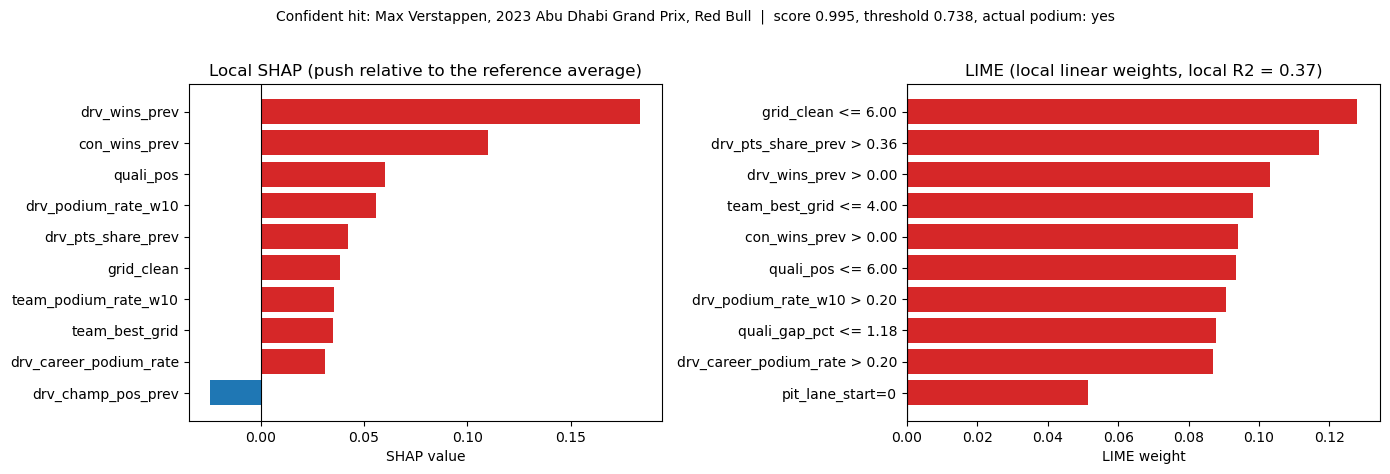

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_missed_podium.png


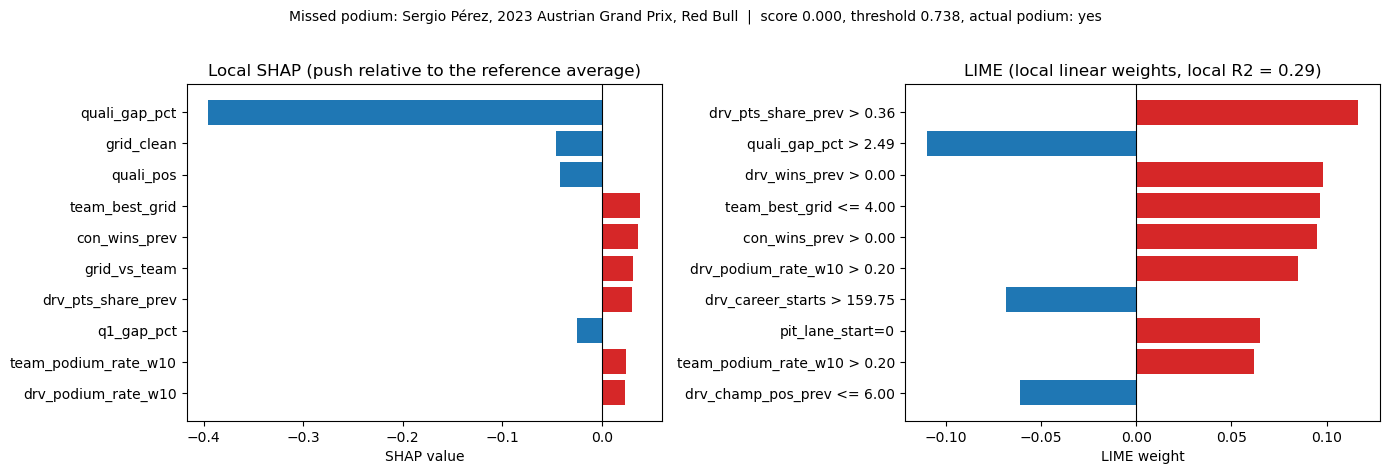

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_false_alarm.png


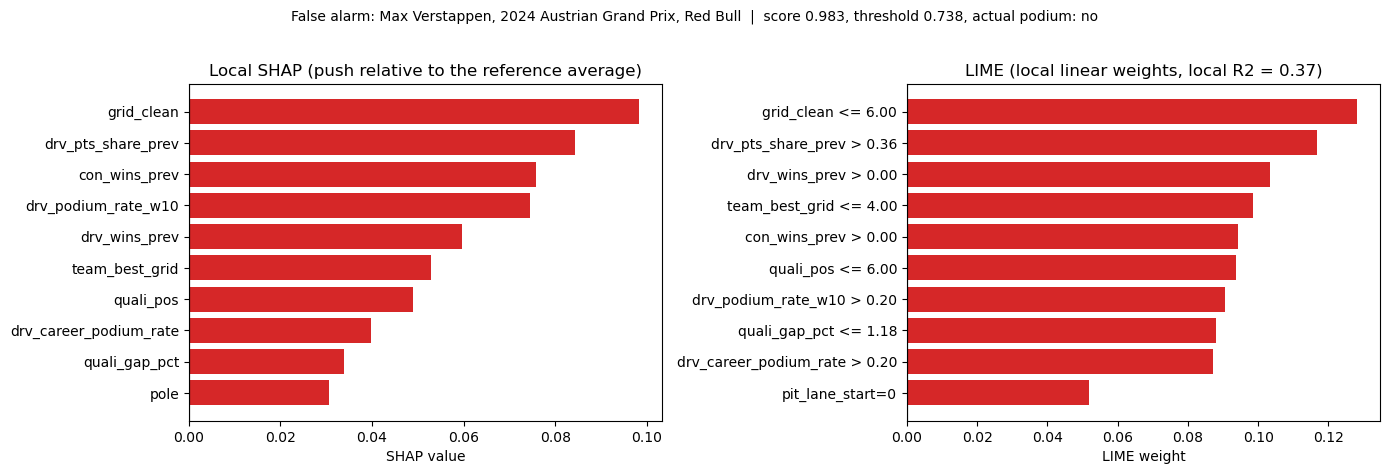

Saved figure: a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai\local_shap_vs_lime_borderline.png


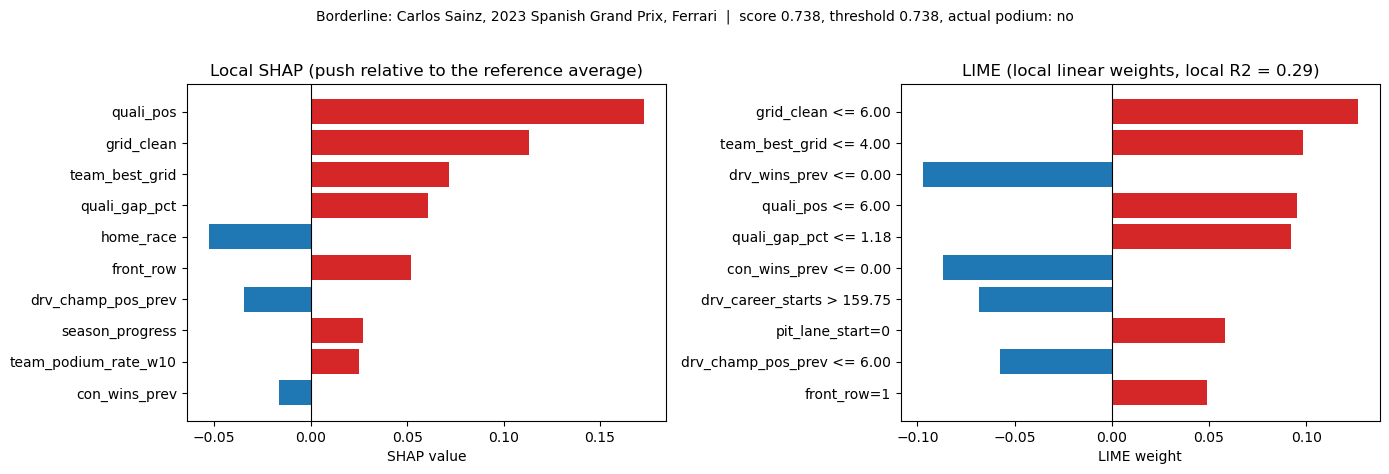

In [23]:
# SHAP and LIME side by side for each case (top 10 features of each)
if HAVE_LIME:
    for name, i in CASES.items():
        sv_i = pd.Series(sv.values[i], index=FEATURES); s10 = sv_i.reindex(sv_i.abs().sort_values(ascending=False).head(10).index)[::-1]
        lw = LIME_RES[name]["weights"]; l10 = lw.reindex(lw.abs().sort_values(ascending=False).index)[::-1]
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
        axes[0].barh(s10.index, s10.values, color=["tab:red" if v > 0 else "tab:blue" for v in s10.values]); axes[0].axvline(0, color="k", lw=0.8)
        axes[0].set_title("Local SHAP (push relative to the reference average)"); axes[0].set_xlabel("SHAP value")
        axes[1].barh([LIME_RES[name]["desc"][f] for f in l10.index], l10.values, color=["tab:red" if v > 0 else "tab:blue" for v in l10.values]); axes[1].axvline(0, color="k", lw=0.8)
        axes[1].set_title(f"LIME (local linear weights, local R2 = {LIME_RES[name]['r2']:.2f})"); axes[1].set_xlabel("LIME weight")
        fig.suptitle(f"{name}: {case_label(i)}  |  score {p_ex[i]:.3f}, threshold {thr:.3f}, actual podium: {'yes' if y_ex[i] else 'no'}", fontsize=10, y=1.02)
        fig.tight_layout(); save_fig(fig, f"local_shap_vs_lime_{name.lower().replace(' ', '_')}.png")

## 15.8 Conclusions (computed from the results above), limitations, saved files

The paragraph printed by the next cell is generated from the tables and checks above, so every number in it matches the figures. Copy it into the report and add the domain reading of the top features yourself (why a front-row start or a strong team record would matter in Formula 1). **It describes the model's behaviour, not causes.**

In [24]:
pi_t = PI["test"].sort_values("pr_auc_drop", ascending=False); top3p = pi_t.head(3)
lines = []
lines.append(f"Model explained: {LABEL[EXPLAIN_KEY]} (test PR-AUC {base_scores['test']['pr_auc']:.3f}, validation {base_scores['validation']['pr_auc']:.3f}; "
             f"rank {test_rank.index(EXPLAIN_KEY) + 1} of {len(test_rank)} on test PR-AUC among the saved models).")
lines.append("Permutation importance (test): the three features whose shuffling hurts PR-AUC most are "
             + ", ".join(f"{r.feature} ({r.pr_auc_drop:.3f})" for r in top3p.itertuples()) + f". {int(pi_t['reliable'].sum())} of {len(pi_t)} features are reliably used (mean drop above 2 standard deviations); "
             f"the rest could be shuffled without a detectable loss.")
vt_word = "agree closely" if AG_VT["spearman_top"] >= 0.8 else "agree partly" if AG_VT["spearman_top"] >= 0.5 else "disagree"
lines.append(f"The validation and test rankings {vt_word} (Spearman {AG_VT['spearman_top']:.2f} over the top-10 union, {AG_VT['overlap_top']} of the top 10 shared).")
g1 = GPI["test"].iloc[0]; lines.append(f"By feature group, shuffling '{g1.group}' costs the most PR-AUC ({g1.pr_auc_drop:.3f}); in descending order: " + ", ".join(f"{r.group} ({r.pr_auc_drop:.3f})" for r in GPI["test"].itertuples()) + ".")
lines.append("SHAP (test rows): the largest mean |SHAP| belong to " + ", ".join(f"{r.feature} ({r.mean_abs_shap:.3f}, {r.share_of_total:.0%} of the total)" for r in shap_tab.head(3).itertuples())
             + f". By group the largest is '{group_shap.iloc[0]['group']}' ({group_shap.iloc[0]['share_of_total']:.0%} of total group SHAP).")
ps_word = "rank features similarly" if AG_PS["spearman_top"] >= 0.8 else "agree only partly on the ranking" if AG_PS["spearman_top"] >= 0.5 else "disagree on the ranking"
lines.append(f"Permutation importance and SHAP {ps_word} (Spearman {AG_PS['spearman_top']:.2f} over the top-10 union, {AG_PS['overlap_top']} of the top 10 shared)" + ("." if ps_word == "rank features similarly" else "; a feature ranked much higher by SHAP than by permutation is one the model pushes on without that push improving test accuracy much."))
lines.append(f"The SHAP ranking is {'robust' if BG_MIN_RHO >= 0.85 else 'moderately sensitive' if BG_MIN_RHO >= 0.7 else 'sensitive'} to the reference data (lowest pairwise Spearman across three references: {BG_MIN_RHO:.2f}; robust at 0.85 or above).")
if XGB_SHAP is not None:
    lines.append(f"An independent TreeSHAP run on XGBoost gives a {'similar' if AG_X['spearman_top'] >= 0.8 else 'partly similar' if AG_X['spearman_top'] >= 0.5 else 'different'} ranking (Spearman {AG_X['spearman_top']:.2f} over the top-10 union, {AG_X['overlap_top']} of the top 10 shared).")
if SEED_AGREE is not None:
    lines.append(f"Across three retrained network seeds (and the saved model) the permutation rankings have pairwise Spearman between {SEED_AGREE['spearman_top'].min():.2f} and {SEED_AGREE['spearman_top'].max():.2f} over the top-10 union, "
                 f"and share at least {int(SEED_AGREE['overlap_top'].min())} of their top 10 features: a network explanation is {'stable' if SEED_AGREE['spearman_top'].min() >= 0.8 else 'only moderately stable' if SEED_AGREE['spearman_top'].min() >= 0.5 else 'not stable'} across seeds.")
if HAVE_LIME and LIME_CMP:
    lc = pd.DataFrame(LIME_CMP)
    lines.append(f"Local: SHAP and LIME share on average {lc['top5_overlap_shap_lime'].mean():.1f} of their top-5 features across the four cases, agree in sign on {lc['sign_agreement_on_lime_top10'].mean():.0%} of LIME's top-10 features, "
                 f"LIME's local R2 averages {lc['lime_local_R2'].mean():.2f} and its top-5 set is {lc['lime_top5_stability_jaccard'].mean():.0%} stable across seeds (Jaccard).")
lines.append("None of these results are causal effects: a feature is important here only in the sense that this fitted model's scores depend on it.")
CONCLUSIONS = "\n\n".join(lines); print(CONCLUSIONS)

Model explained: Shallow NN (test PR-AUC 0.689, validation 0.748; rank 1 of 1 on test PR-AUC among the saved models).

Permutation importance (test): the three features whose shuffling hurts PR-AUC most are quali_pos (0.071), grid_clean (0.064), team_best_grid (0.031). 9 of 29 features are reliably used (mean drop above 2 standard deviations); the rest could be shuffled without a detectable loss.

The validation and test rankings disagree (Spearman 0.01 over the top-10 union, 6 of the top 10 shared).

By feature group, shuffling 'grid' costs the most PR-AUC (0.178); in descending order: grid (0.178), standings (0.080), qualifying (0.072), context (0.011), constructor_form (0.011), driver_form (0.010), circuit_history (-0.006).

SHAP (test rows): the largest mean |SHAP| belong to grid_clean (0.059, 11% of the total), quali_pos (0.059, 11% of the total), team_best_grid (0.048, 9% of the total). By group the largest is 'grid' (29% of total group SHAP).

Permutation importance and SHAP dis

### Limitations to state in the report

1. **Not causal.** Importance, SHAP values and LIME weights describe how the fitted model maps inputs to scores. A high-importance feature may be a proxy for something unmeasured (car pace, tyre strategy), and nothing here supports the claim that changing it would change a race result.
2. **Correlated features.** Starting slot, qualifying position, team form and standings carry overlapping information. Single-feature importances split or hide credit; the group-level results are the safer thing to quote.
3. **Unrealistic perturbations.** Permutation importance, permutation SHAP and LIME all evaluate the model on feature combinations that never occur (a pole sitter with an impossible team record). Model behaviour in those regions can be arbitrary, so very small importances should not be over-read.
4. **Reference data and era.** SHAP is relative to a reference population (hybrid-era training rows). The test seasons use new regulations; the model was trained mostly on earlier cars, so explanations describe how an earlier-era model scores new-era rows, not how the new era works.
5. **Scores are not calibrated.** Class up-weighting inflates scores; SHAP magnitudes are in score units.
6. **One network, one seed.** The saved network is a single draw; the seed check bounds how much that matters, but it is not an interval around the true relationship.
7. **Small test set.** About three seasons of races. Importance differences of a few thousandths of PR-AUC are within the spread shown by the error bars.
8. **LIME** is stochastic, is fitted on binned values, and had its few missing inputs filled; it is shown as a second opinion on individual cases, not as ground truth.
9. **Explaining the final model, not the best test model.** If the final model chosen on validation is not the best on test, say so explicitly; the cross-model comparison in 15.3.2 and the XGBoost cross-check in 15.6.2 are there so the conclusions do not hang on one model.

In [25]:
# ---- save everything the report needs -----------------------------------------------------------------------------
def save_tab(df, name, index=False):
    p = os.path.join(TAB_DIR, name); df.to_csv(p, index=index); return name
saved = [save_tab(PI_TABLE, "permutation_importance_features.csv"), save_tab(GROUP_PI_TABLE, "permutation_importance_groups.csv"),
         save_tab(cross_mat.reset_index().rename(columns={"index": "feature"}), "permutation_importance_cross_model.csv"),
         save_tab(shap_tab, "shap_global_importance.csv"), save_tab(group_shap, "shap_group_importance.csv"),
         save_tab(cmp.reset_index().rename(columns={"index": "feature"}), "permutation_vs_shap.csv"),
         save_tab(bg_imp.reset_index().rename(columns={"index": "feature"}), "shap_background_sensitivity.csv"),
         save_tab(case_df, "local_cases.csv")]
if SEED_RANK is not None: saved.append(save_tab(SEED_RANK.reset_index().rename(columns={"index": "feature"}), "permutation_importance_seeds.csv"))
if HAVE_LIME and LIME_CMP: saved.append(save_tab(pd.DataFrame(LIME_CMP), "local_shap_vs_lime.csv"))
if XGB_SHAP is not None: saved.append(save_tab(xgb_tab.reset_index().rename(columns={"index": "feature"}), "shap_xgboost_crosscheck.csv"))
shap_df = pd.DataFrame(sv.values, columns=FEATURES); shap_df.insert(0, "resultId", ex["resultId"].to_numpy()); shap_df["base_value"] = sv.base_values; shap_df["model_score"] = p_ex
shap_df.to_parquet(os.path.join(TAB_DIR, "shap_values_test.parquet"), index=False); saved.append("shap_values_test.parquet")
json.dump(dict(explained_model=EXPLAIN_KEY, label=LABEL[EXPLAIN_KEY], threshold=thr, reference_rows=len(bg_df), shap_permutations=N_PERMUTATIONS,
               additivity_max_error=add_err, base_value=base_val, conclusions=CONCLUSIONS.split("\n\n")), open(os.path.join(TAB_DIR, "xai_summary.json"), "w"), indent=2)
saved.append("xai_summary.json")
print("tables saved to", TAB_DIR, "->", saved)
print("figures saved to", FIG_DIR, "->", sorted(os.listdir(FIG_DIR)))

tables saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\xai_outputs -> ['permutation_importance_features.csv', 'permutation_importance_groups.csv', 'permutation_importance_cross_model.csv', 'shap_global_importance.csv', 'shap_group_importance.csv', 'permutation_vs_shap.csv', 'shap_background_sensitivity.csv', 'local_cases.csv', 'permutation_importance_seeds.csv', 'local_shap_vs_lime.csv', 'shap_values_test.parquet', 'xai_summary.json']
figures saved to a:\College\Sem 9\CSEN903 ACL\Project\MS1\Formula-1-Podium-Prediction-Companion\figures_xai -> ['local_shap_vs_lime_borderline.png', 'local_shap_vs_lime_confident_hit.png', 'local_shap_vs_lime_false_alarm.png', 'local_shap_vs_lime_missed_podium.png', 'perm_importance_cross_model.png', 'perm_importance_groups.png', 'perm_importance_seeds.png', 'perm_importance_val_test.png', 'perm_vs_shap.png', 'shap_bar.png', 'shap_beeswarm.png', 'shap_dependence_top4.png', 'shap_groups.png', 'shap_waterfall_borderli